In [1]:
!pip install numpy scipy pandas matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.6 MB 9.7 MB/s eta 0:00:01
   ------------- -------------------------- 3.1/9.6 MB 8.0 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.6 MB 7.7 MB/s eta 0:00:01
   ----------------------- ---------------- 5.8/9.6 MB 7.5 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.6 MB 6.9 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.6 MB 6.6 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.6 MB 6.2 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.6 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 5.4 MB/s  0:00:01
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 

### Loading and inspecting the .mat file

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import loadmat

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
file_path = r"C:\Users\sabba\Downloads\DREAMER.mat"

print(file_path)

C:\Users\sabba\Downloads\DREAMER.mat


In [4]:

import scipy
# Load the DREAMER mat file
mat_data = scipy.io.loadmat(file_path)

# View available keys in the loaded dictionary
print(mat_data.keys())


dict_keys(['__header__', '__version__', '__globals__', 'DREAMER'])


In [5]:
# Access the main DREAMER data array
dreamer = mat_data["DREAMER"]

# Inspect data shapes or individual participant trials
# e.g., dreamer[0, 0]['Data'] contains participant-specific trials
print(dreamer.shape)


(1, 1)


In [6]:
import os

if os.path.exists(file_path):
    print("DREAMER.mat found!")
    print("File size:", round(os.path.getsize(file_path) / (1024**2), 2), "MB")
else:
    print("File not found. Check the file path.")

DREAMER.mat found!
File size: 431.87 MB


In [7]:
from scipy.io import loadmat

dreamer = loadmat(file_path)

print("DREAMER file loaded successfully!")

DREAMER file loaded successfully!


In [8]:
DREAMER = dreamer['DREAMER']

print("Type:", type(DREAMER))
print("Shape:", DREAMER.shape)

Type: <class 'numpy.ndarray'>
Shape: (1, 1)


In [9]:
print(DREAMER.dtype)

[('Data', 'O'), ('EEG_SamplingRate', 'O'), ('ECG_SamplingRate', 'O'), ('EEG_Electrodes', 'O'), ('noOfSubjects', 'O'), ('noOfVideoSequences', 'O'), ('Disclaimer', 'O'), ('Provider', 'O'), ('Version', 'O'), ('Acknowledgement', 'O')]


### Structure of Dataset

In [10]:
fields = DREAMER.dtype.names

print("Fields in DREAMER:")
for i, field in enumerate(fields, 1):
    print(f"{i}. {field}")

Fields in DREAMER:
1. Data
2. EEG_SamplingRate
3. ECG_SamplingRate
4. EEG_Electrodes
5. noOfSubjects
6. noOfVideoSequences
7. Disclaimer
8. Provider
9. Version
10. Acknowledgement


In [11]:
print("Number of subjects:", DREAMER['noOfSubjects'][0, 0])
print("Number of video sequences:", DREAMER['noOfVideoSequences'][0, 0])
print("EEG sampling rate:", DREAMER['EEG_SamplingRate'][0, 0])
print("ECG sampling rate:", DREAMER['ECG_SamplingRate'][0, 0])

Number of subjects: [[23]]
Number of video sequences: [[18]]
EEG sampling rate: [[128]]
ECG sampling rate: [[256]]


In [12]:
electrodes = DREAMER['EEG_Electrodes'][0, 0]

print("EEG Electrodes:")
print(electrodes)

EEG Electrodes:
[[array(['AF3'], dtype='<U3') array(['F7'], dtype='<U2')
  array(['F3'], dtype='<U2') array(['FC5'], dtype='<U3')
  array(['T7'], dtype='<U2') array(['P7'], dtype='<U2')
  array(['O1'], dtype='<U2') array(['O2'], dtype='<U2')
  array(['P8'], dtype='<U2') array(['T8'], dtype='<U2')
  array(['FC6'], dtype='<U3') array(['F4'], dtype='<U2')
  array(['F8'], dtype='<U2') array(['AF4'], dtype='<U3')]]


In [13]:
data = DREAMER['Data'][0, 0]

print("Type:", type(data))
print("Shape:", data.shape)
print("Data type:", data.dtype)

Type: <class 'numpy.ndarray'>
Shape: (1, 23)
Data type: object


In [14]:
subject1 = data[0, 0]

print("Subject 1:")
print(subject1)

Subject 1:
[[(array(['22'], dtype='<U2'), array(['male'], dtype='<U4'), array([[(array([[array([[4390.25641026, 4097.43589744, 4267.69230769, ..., 4512.30769231,
                          4368.71794872, 4287.69230769],
                         [4397.43589744, 4095.8974359 , 4248.20512821, ..., 4506.15384615,
                          4272.82051282, 4187.69230769],
                         [4391.79487179, 4091.28205128, 4261.02564103, ..., 4494.87179487,
                          4342.56410256, 4256.41025641],
                         ...,
                         [4392.82051282, 4107.17948718, 4288.71794872, ..., 4532.82051282,
                          4395.38461538, 4307.17948718],
                         [4385.64102564, 4108.71794872, 4328.20512821, ..., 4542.56410256,
                          4468.71794872, 4431.79487179],
                         [4382.56410256, 4108.71794872, 4385.12820513, ..., 4573.33333333,
                          4560.51282051, 4549.23076923]])           

In [15]:
print("Subject 1 fields:")

for i, field in enumerate(subject1.dtype.names, 1):
    print(f"{i}. {field}")

Subject 1 fields:
1. Age
2. Gender
3. EEG
4. ECG
5. ScoreValence
6. ScoreArousal
7. ScoreDominance


In [16]:
for field in subject1.dtype.names:
    value = subject1[field][0, 0]
    
    if hasattr(value, 'shape'):
        print(f"{field}: shape = {value.shape}")
    else:
        print(f"{field}: {type(value)}")

Age: shape = (1,)
Gender: shape = (1,)
EEG: shape = (1, 1)
ECG: shape = (1, 1)
ScoreValence: shape = (18, 1)
ScoreArousal: shape = (18, 1)
ScoreDominance: shape = (18, 1)


In [17]:
print("=" * 50)
print("DREAMER DATASET STRUCTURE")
print("=" * 50)

print("Subjects:", DREAMER['noOfSubjects'][0, 0])
print("Videos:", DREAMER['noOfVideoSequences'][0, 0])
print("EEG Sampling Rate:", DREAMER['EEG_SamplingRate'][0, 0], "Hz")
print("ECG Sampling Rate:", DREAMER['ECG_SamplingRate'][0, 0], "Hz")

print("\nSubject 1 contains:")
for field in subject1.dtype.names:
    print("-", field)

DREAMER DATASET STRUCTURE
Subjects: [[23]]
Videos: [[18]]
EEG Sampling Rate: [[128]] Hz
ECG Sampling Rate: [[256]] Hz

Subject 1 contains:
- Age
- Gender
- EEG
- ECG
- ScoreValence
- ScoreArousal
- ScoreDominance


### Analyzing subjects and emotion ratings

In [18]:
n_subjects = int(DREAMER['noOfSubjects'][0, 0].item())
n_videos = int(DREAMER['noOfVideoSequences'][0, 0].item())

print("Number of subjects:", n_subjects)
print("Number of videos:", n_videos)
print("Total subject-video trials:", n_subjects * n_videos)

Number of subjects: 23
Number of videos: 18
Total subject-video trials: 414


In [19]:
for i in range(n_subjects):
    subject = data[0, i]

    age = subject['Age'][0, 0]
    gender = subject['Gender'][0, 0]

    print(f"Subject {i+1}: Age = {age}, Gender = {gender}")

Subject 1: Age = ['22'], Gender = ['male']
Subject 2: Age = ['30'], Gender = ['female']
Subject 3: Age = ['27'], Gender = ['male']
Subject 4: Age = ['26'], Gender = ['female']
Subject 5: Age = ['27'], Gender = ['female']
Subject 6: Age = ['25'], Gender = ['male']
Subject 7: Age = ['23'], Gender = ['female']
Subject 8: Age = ['29'], Gender = ['male']
Subject 9: Age = ['31'], Gender = ['female']
Subject 10: Age = ['24'], Gender = ['male']
Subject 11: Age = ['26'], Gender = ['male']
Subject 12: Age = ['25'], Gender = ['male']
Subject 13: Age = ['28'], Gender = ['male']
Subject 14: Age = ['25'], Gender = ['male']
Subject 15: Age = ['29'], Gender = ['male']
Subject 16: Age = ['28'], Gender = ['female']
Subject 17: Age = ['26'], Gender = ['female']
Subject 18: Age = ['25'], Gender = ['female']
Subject 19: Age = ['33'], Gender = ['male']
Subject 20: Age = ['23'], Gender = ['female']
Subject 21: Age = ['26'], Gender = ['male']
Subject 22: Age = ['28'], Gender = ['male']
Subject 23: Age = ['25'

In [20]:
subjects = []

for i in range(n_subjects):
    subject = data[0, i]

    age = np.asarray(subject['Age']).squeeze()
    gender = np.asarray(subject['Gender']).squeeze()

    subjects.append({
        'Subject': i + 1,
        'Age': age,
        'Gender': gender
    })

subjects_df = pd.DataFrame(subjects)

subjects_df

,Subject,Age,Gender
0,1,['22'],['male']
1,2,['30'],['female']
2,3,['27'],['male']
3,4,['26'],['female']
4,5,['27'],['female']
5,6,['25'],['male']
6,7,['23'],['female']
7,8,['29'],['male']
8,9,['31'],['female']
9,10,['24'],['male']


In [21]:
# Inspect Age and Gender for the first few subjects

for i in range(5):
    subject = data[0, i]

    print(f"\nSubject {i+1}")
    print("Age raw:", subject['Age'])
    print("Age shape:", subject['Age'].shape)
    print("Age type:", type(subject['Age']))
    
    print("Gender raw:", subject['Gender'])
    print("Gender shape:", subject['Gender'].shape)


Subject 1
Age raw: [[array(['22'], dtype='<U2')]]
Age shape: (1, 1)
Age type: <class 'numpy.ndarray'>
Gender raw: [[array(['male'], dtype='<U4')]]
Gender shape: (1, 1)

Subject 2
Age raw: [[array(['30'], dtype='<U2')]]
Age shape: (1, 1)
Age type: <class 'numpy.ndarray'>
Gender raw: [[array(['female'], dtype='<U6')]]
Gender shape: (1, 1)

Subject 3
Age raw: [[array(['27'], dtype='<U2')]]
Age shape: (1, 1)
Age type: <class 'numpy.ndarray'>
Gender raw: [[array(['male'], dtype='<U4')]]
Gender shape: (1, 1)

Subject 4
Age raw: [[array(['26'], dtype='<U2')]]
Age shape: (1, 1)
Age type: <class 'numpy.ndarray'>
Gender raw: [[array(['female'], dtype='<U6')]]
Gender shape: (1, 1)

Subject 5
Age raw: [[array(['27'], dtype='<U2')]]
Age shape: (1, 1)
Age type: <class 'numpy.ndarray'>
Gender raw: [[array(['female'], dtype='<U6')]]
Gender shape: (1, 1)


In [22]:
print("Subject 1 Age:")
print(data[0, 0]['Age'])

print("\nSubject 1 Gender:")
print(data[0, 0]['Gender'])

Subject 1 Age:
[[array(['22'], dtype='<U2')]]

Subject 1 Gender:
[[array(['male'], dtype='<U4')]]


In [23]:
print(subjects_df['Gender'].value_counts())

Gender
['male']      14
['female']     9
Name: count, dtype: int64


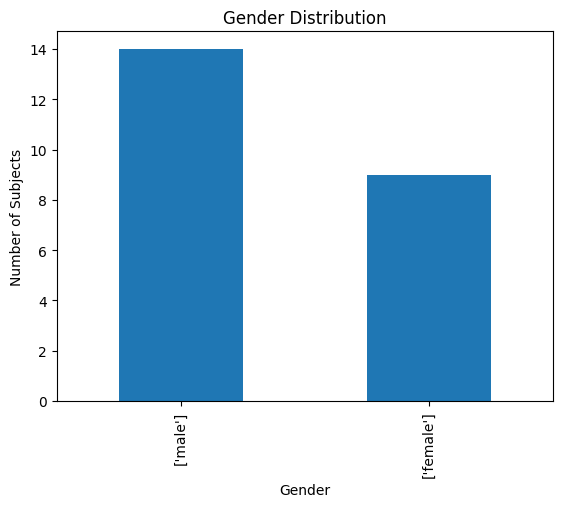

In [24]:
subjects_df['Gender'].value_counts().plot(kind='bar')

plt.xlabel('Gender')
plt.ylabel('Number of Subjects')
plt.title('Gender Distribution')
plt.show()

In [25]:
subject1 = data[0, 0]

print("ScoreValence raw:")
print(subject1['ScoreValence'])
print("Type:", type(subject1['ScoreValence']))
print("Shape:", subject1['ScoreValence'].shape)

print("\nScoreArousal raw:")
print(subject1['ScoreArousal'])
print("Type:", type(subject1['ScoreArousal']))
print("Shape:", subject1['ScoreArousal'].shape)

print("\nScoreDominance raw:")
print(subject1['ScoreDominance'])
print("Type:", type(subject1['ScoreDominance']))
print("Shape:", subject1['ScoreDominance'].shape)

ScoreValence raw:
[[array([[4],
         [3],
         [5],
         [4],
         [4],
         [1],
         [5],
         [1],
         [1],
         [5],
         [4],
         [4],
         [4],
         [3],
         [2],
         [3],
         [1],
         [3]], dtype=uint8)]]
Type: <class 'numpy.ndarray'>
Shape: (1, 1)

ScoreArousal raw:
[[array([[3],
         [3],
         [4],
         [3],
         [4],
         [2],
         [4],
         [2],
         [2],
         [3],
         [2],
         [3],
         [3],
         [1],
         [5],
         [2],
         [2],
         [5]], dtype=uint8)]]
Type: <class 'numpy.ndarray'>
Shape: (1, 1)

ScoreDominance raw:
[[array([[2],
         [1],
         [4],
         [2],
         [4],
         [5],
         [4],
         [4],
         [3],
         [4],
         [3],
         [4],
         [2],
         [2],
         [5],
         [2],
         [5],
         [5]], dtype=uint8)]]
Type: <class 'numpy.ndarray'>
Shape: (1, 1)


In [26]:
print("\nNested value types:")

for field in ['ScoreValence', 'ScoreArousal', 'ScoreDominance']:
    x = subject1[field]
    print(field)
    print("  x:", type(x), getattr(x, 'shape', None))
    
    if isinstance(x, np.ndarray):
        print("  x.item():", type(x.item()), getattr(x.item(), 'shape', None))
        print("  x.item():", x.item())


Nested value types:
ScoreValence
  x: <class 'numpy.ndarray'> (1, 1)
  x.item(): <class 'numpy.ndarray'> (18, 1)
  x.item(): [[4]
 [3]
 [5]
 [4]
 [4]
 [1]
 [5]
 [1]
 [1]
 [5]
 [4]
 [4]
 [4]
 [3]
 [2]
 [3]
 [1]
 [3]]
ScoreArousal
  x: <class 'numpy.ndarray'> (1, 1)
  x.item(): <class 'numpy.ndarray'> (18, 1)
  x.item(): [[3]
 [3]
 [4]
 [3]
 [4]
 [2]
 [4]
 [2]
 [2]
 [3]
 [2]
 [3]
 [3]
 [1]
 [5]
 [2]
 [2]
 [5]]
ScoreDominance
  x: <class 'numpy.ndarray'> (1, 1)
  x.item(): <class 'numpy.ndarray'> (18, 1)
  x.item(): [[2]
 [1]
 [4]
 [2]
 [4]
 [5]
 [4]
 [4]
 [3]
 [4]
 [3]
 [4]
 [2]
 [2]
 [5]
 [2]
 [5]
 [5]]


In [27]:
valence = subject1['ScoreValence'].item().flatten()
arousal = subject1['ScoreArousal'].item().flatten()
dominance = subject1['ScoreDominance'].item().flatten()

In [28]:
subject1 = data[0, 0]

valence = subject1['ScoreValence'].item().flatten()
arousal = subject1['ScoreArousal'].item().flatten()
dominance = subject1['ScoreDominance'].item().flatten()

print("Valence shape:", valence.shape)
print("Arousal shape:", arousal.shape)
print("Dominance shape:", dominance.shape)

print("\nValence:", valence)
print("Arousal:", arousal)
print("Dominance:", dominance)

Valence shape: (18,)
Arousal shape: (18,)
Dominance shape: (18,)

Valence: [4 3 5 4 4 1 5 1 1 5 4 4 4 3 2 3 1 3]
Arousal: [3 3 4 3 4 2 4 2 2 3 2 3 3 1 5 2 2 5]
Dominance: [2 1 4 2 4 5 4 4 3 4 3 4 2 2 5 2 5 5]


In [29]:
subject1_trials = pd.DataFrame({
    'Video': np.arange(1, n_videos + 1),
    'Valence': valence,
    'Arousal': arousal,
    'Dominance': dominance
})

subject1_trials

,Video,Valence,Arousal,Dominance
0,1,4,3,2
1,2,3,3,1
2,3,5,4,4
3,4,4,3,2
4,5,4,4,4
5,6,1,2,5
6,7,5,4,4
7,8,1,2,4
8,9,1,2,3
9,10,5,3,4


In [30]:
all_labels = []

for s in range(n_subjects):
    subject = data[0, s]

    valence = subject['ScoreValence'].item().flatten()
    arousal = subject['ScoreArousal'].item().flatten()
    dominance = subject['ScoreDominance'].item().flatten()

    for v in range(n_videos):
        all_labels.append({
            'Subject': s + 1,
            'Video': v + 1,
            'Valence': int(valence[v]),
            'Arousal': int(arousal[v]),
            'Dominance': int(dominance[v])
        })

labels_df = pd.DataFrame(all_labels)

print("Shape:", labels_df.shape)
print("\nFirst 10 trials:")
display(labels_df.head(10))

print("\nLast 10 trials:")
display(labels_df.tail(10))

Shape: (414, 5)

First 10 trials:


,Subject,Video,Valence,Arousal,Dominance
0,1,1,4,3,2
1,1,2,3,3,1
2,1,3,5,4,4
3,1,4,4,3,2
4,1,5,4,4,4
5,1,6,1,2,5
6,1,7,5,4,4
7,1,8,1,2,4
8,1,9,1,2,3
9,1,10,5,3,4



Last 10 trials:


,Subject,Video,Valence,Arousal,Dominance
404,23,9,2,2,2
405,23,10,2,5,5
406,23,11,4,1,1
407,23,12,4,2,2
408,23,13,4,3,3
409,23,14,2,2,2
410,23,15,2,2,2
411,23,16,3,3,2
412,23,17,2,2,4
413,23,18,2,4,2


In [31]:
print("Valence values:", sorted(labels_df['Valence'].unique()))
print("Arousal values:", sorted(labels_df['Arousal'].unique()))
print("Dominance values:", sorted(labels_df['Dominance'].unique()))

Valence values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Arousal values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Dominance values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [32]:
print(labels_df[['Valence', 'Arousal', 'Dominance']].describe())

          Valence     Arousal   Dominance
count  414.000000  414.000000  414.000000
mean     2.951691    3.229469    3.374396
std      1.319470    1.081655    1.070141
min      1.000000    1.000000    1.000000
25%      2.000000    2.000000    3.000000
50%      3.000000    3.000000    3.000000
75%      4.000000    4.000000    4.000000
max      5.000000    5.000000    5.000000


In [33]:
print(labels_df.isnull().sum())

Subject      0
Video        0
Valence      0
Arousal      0
Dominance    0
dtype: int64


### Analyzing EEG shape

In [34]:
subject1 = data[0, 0]

eeg = subject1['EEG']

print("EEG type:", type(eeg))
print("EEG shape:", eeg.shape)
print("EEG dtype:", eeg.dtype)

EEG type: <class 'numpy.ndarray'>
EEG shape: (1, 1)
EEG dtype: object


In [35]:
eeg_struct = subject1['EEG'].item()

print("EEG structured dtype:")
print(eeg_struct.dtype.names)

baseline = eeg_struct['baseline']
stimuli = eeg_struct['stimuli']

print("\nBaseline:")
print("Type:", type(baseline))
print("Shape:", baseline.shape)
print("Dtype:", baseline.dtype)

print("\nStimuli:")
print("Type:", type(stimuli))
print("Shape:", stimuli.shape)
print("Dtype:", stimuli.dtype)

EEG structured dtype:
('baseline', 'stimuli')

Baseline:
Type: <class 'numpy.ndarray'>
Shape: (1, 1)
Dtype: object

Stimuli:
Type: <class 'numpy.ndarray'>
Shape: (1, 1)
Dtype: object


In [36]:
baseline_data = baseline.item()
stimuli_data = stimuli.item()

print("Baseline item:")
print("Type:", type(baseline_data))
print("Shape:", baseline_data.shape)
print("Dtype:", baseline_data.dtype)

print("\nStimuli item:")
print("Type:", type(stimuli_data))
print("Shape:", stimuli_data.shape)
print("Dtype:", stimuli_data.dtype)

Baseline item:
Type: <class 'numpy.ndarray'>
Shape: (18, 1)
Dtype: object

Stimuli item:
Type: <class 'numpy.ndarray'>
Shape: (18, 1)
Dtype: object


In [37]:
print("\nBaseline first element:")
b0 = baseline_data.flat[0]

print("Type:", type(b0))
print("Shape:", getattr(b0, 'shape', None))
print("Dtype:", getattr(b0, 'dtype', None))

print("\nStimuli first element:")
s0 = stimuli_data.flat[0]

print("Type:", type(s0))
print("Shape:", getattr(s0, 'shape', None))
print("Dtype:", getattr(s0, 'dtype', None))


Baseline first element:
Type: <class 'numpy.ndarray'>
Shape: (7808, 14)
Dtype: float64

Stimuli first element:
Type: <class 'numpy.ndarray'>
Shape: (25472, 14)
Dtype: float64


In [38]:
sampling_rate = 128

baseline_samples = baseline_data[0, 0].shape[0]
stimuli_samples = stimuli_data[0, 0].shape[0]

n_channels = baseline_data[0, 0].shape[1]

baseline_duration = baseline_samples / sampling_rate
stimuli_duration = stimuli_samples / sampling_rate

print("Sampling rate:", sampling_rate, "Hz")
print("Number of EEG channels:", n_channels)

print("\nBaseline:")
print("Samples:", baseline_samples)
print("Duration:", baseline_duration, "seconds")
print("Duration:", baseline_duration / 60, "minutes")

print("\nStimuli:")
print("Samples:", stimuli_samples)
print("Duration:", stimuli_duration, "seconds")
print("Duration:", stimuli_duration / 60, "minutes")

Sampling rate: 128 Hz
Number of EEG channels: 14

Baseline:
Samples: 7808
Duration: 61.0 seconds
Duration: 1.0166666666666666 minutes

Stimuli:
Samples: 25472
Duration: 199.0 seconds
Duration: 3.316666666666667 minutes


In [39]:
channels = [
    'AF3', 'F7', 'F3', 'FC5',
    'T7', 'P7', 'O1', 'O2',
    'P8', 'T8', 'FC6', 'F4',
    'F8', 'AF4'
]

print("Number of channels:", len(channels))

for i, ch in enumerate(channels):
    print(f"Channel {i}: {ch}")

Number of channels: 14
Channel 0: AF3
Channel 1: F7
Channel 2: F3
Channel 3: FC5
Channel 4: T7
Channel 5: P7
Channel 6: O1
Channel 7: O2
Channel 8: P8
Channel 9: T8
Channel 10: FC6
Channel 11: F4
Channel 12: F8
Channel 13: AF4


In [40]:
trial1 = stimuli_data[0, 0]

print("Trial 1 shape:", trial1.shape)
print("\nFirst 5 samples:")
print(trial1[:5])

Trial 1 shape: (25472, 14)

First 5 samples:
[[4388.20512821 4102.56410256 4219.48717949 4465.12820513 4370.76923077
  4399.48717949 4443.07692308 4023.07692308 4365.12820513 4310.25641026
  3953.84615385 4454.35897436 4326.15384615 4165.12820513]
 [4375.8974359  4093.84615385 4252.82051282 4522.56410256 4435.8974359
  4411.79487179 4488.71794872 4108.71794872 4399.48717949 4384.61538462
  4007.69230769 4466.66666667 4372.82051282 4247.17948718]
 [4378.46153846 4091.28205128 4230.25641026 4488.20512821 4370.25641026
  4402.56410256 4461.02564103 4077.43589744 4378.46153846 4328.71794872
  3986.15384615 4461.02564103 4328.20512821 4203.58974359]
 [4393.84615385 4101.02564103 4193.33333333 4418.97435897 4270.25641026
  4392.30769231 4411.28205128 3982.56410256 4336.41025641 4213.33333333
  3930.25641026 4442.56410256 4261.02564103 4100.        ]
 [4396.41025641 4108.71794872 4210.76923077 4436.41025641 4310.76923077
  4401.02564103 4426.66666667 3980.51282051 4349.74358974 4238.46153846


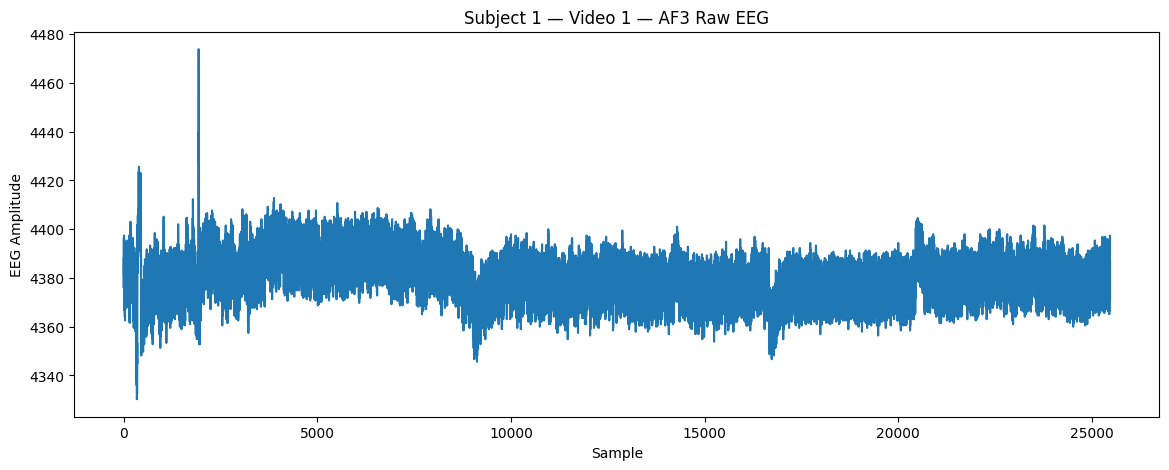

In [41]:
plt.figure(figsize=(14, 5))

plt.plot(trial1[:, 0])

plt.xlabel("Sample")
plt.ylabel("EEG Amplitude")
plt.title("Subject 1 — Video 1 — AF3 Raw EEG")

plt.show()

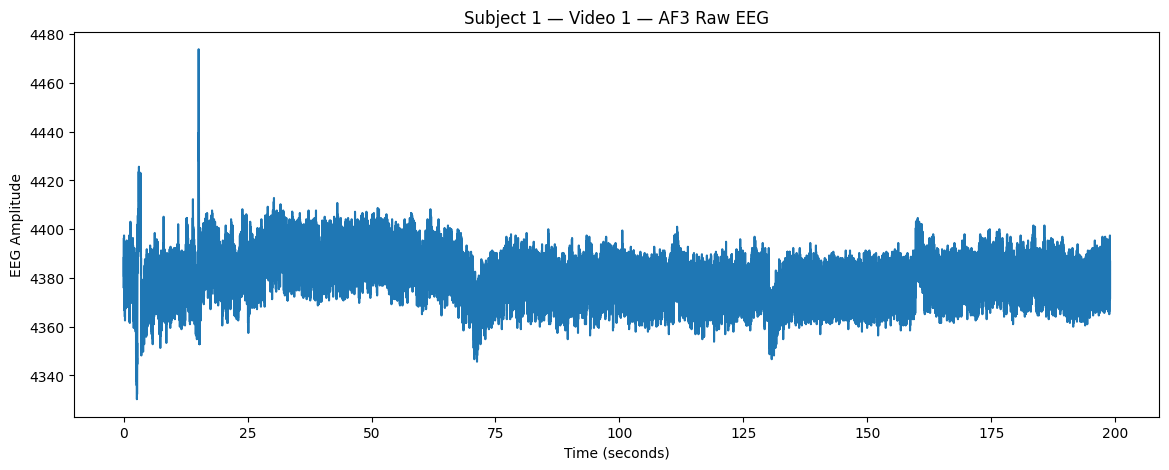

In [42]:
time = np.arange(trial1.shape[0]) / sampling_rate

plt.figure(figsize=(14, 5))

plt.plot(time, trial1[:, 0])

plt.xlabel("Time (seconds)")
plt.ylabel("EEG Amplitude")
plt.title("Subject 1 — Video 1 — AF3 Raw EEG")

plt.show()

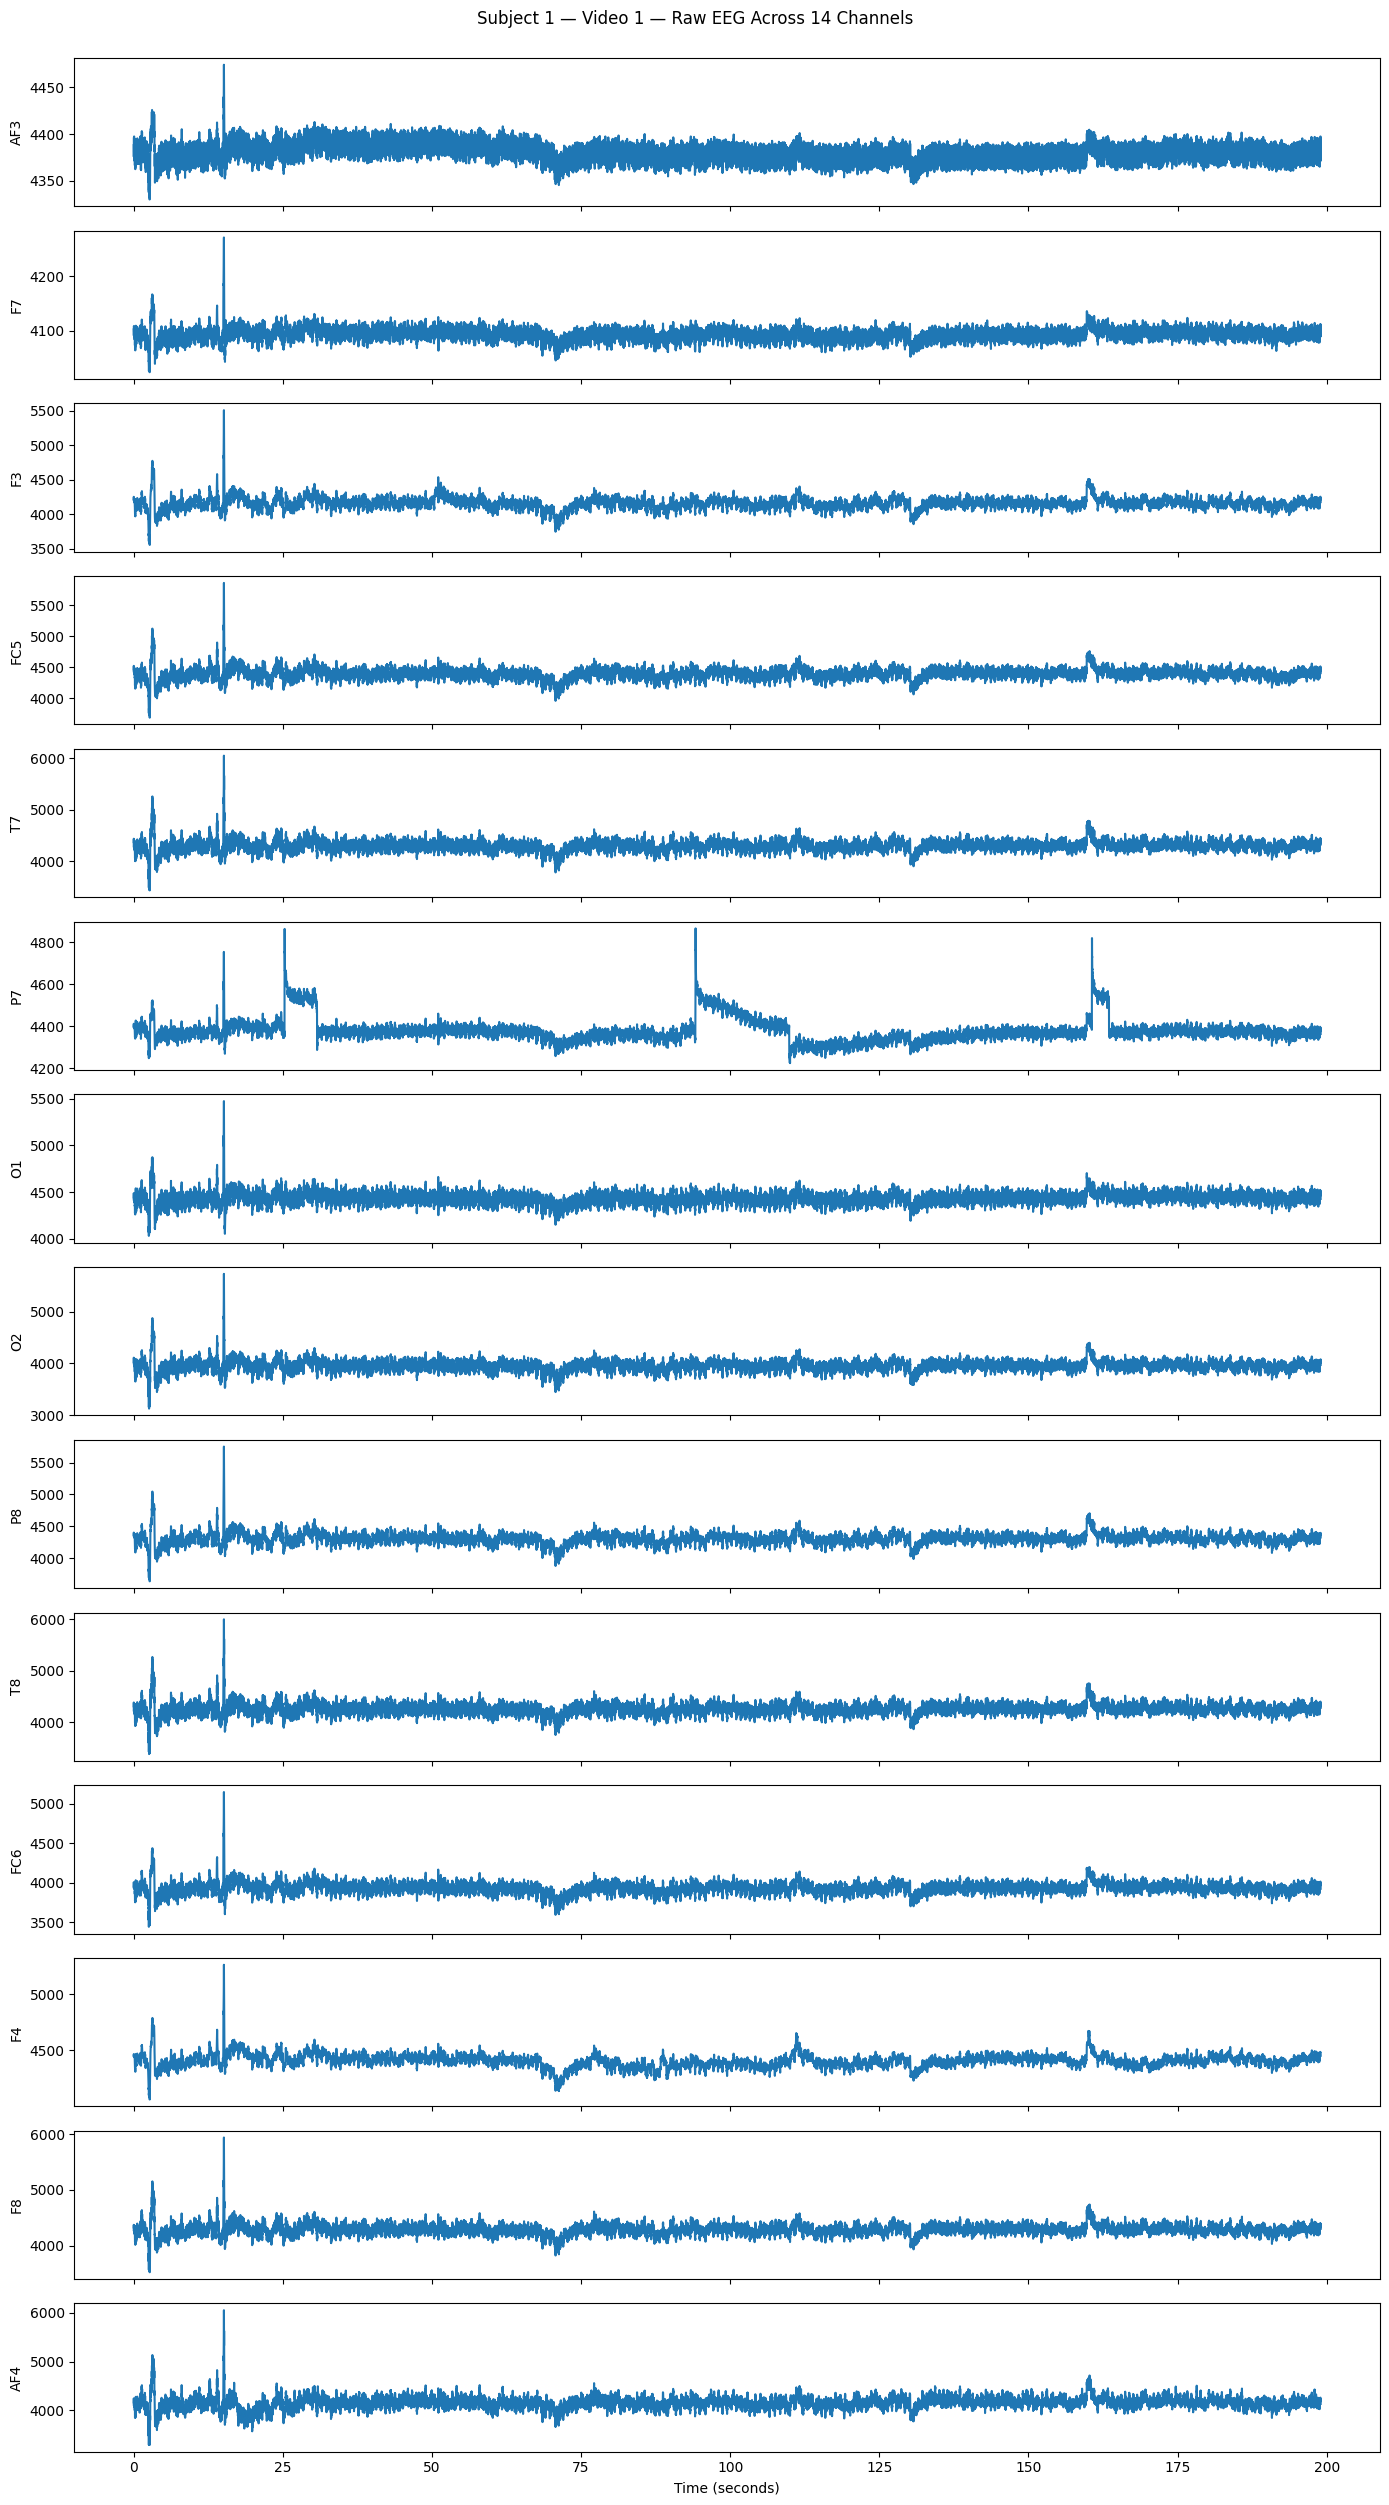

In [43]:
fig, axes = plt.subplots(14, 1, figsize=(14, 25), sharex=True)

for i in range(14):
    axes[i].plot(time, trial1[:, i])
    axes[i].set_ylabel(channels[i])

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle(
    "Subject 1 — Video 1 — Raw EEG Across 14 Channels",
    y=1.0
)

plt.tight_layout()
plt.show()

### EEG Preprocessing

In [44]:
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

In [45]:
# Extracting Subject 1, Video 1 EEG
subject1 = data[0, 0]

eeg_struct = subject1['EEG'].item()

baseline_data = eeg_struct['baseline'].item()
stimuli_data = eeg_struct['stimuli'].item()

baseline_trial = baseline_data[0, 0]
stimulus_trial = stimuli_data[0, 0]

print("Baseline shape:", baseline_trial.shape)
print("Stimulus shape:", stimulus_trial.shape)

Baseline shape: (7808, 14)
Stimulus shape: (25472, 14)


In [46]:
# Define sampling rate and channels
sampling_rate = 128

channels = [
    'AF3', 'F7', 'F3', 'FC5',
    'T7', 'P7', 'O1', 'O2',
    'P8', 'T8', 'FC6', 'F4',
    'F8', 'AF4'
]

print("Sampling rate:", sampling_rate, "Hz")
print("Number of channels:", len(channels))

Sampling rate: 128 Hz
Number of channels: 14


In [47]:
# Calculate baseline statistics
baseline_mean = np.mean(baseline_trial, axis=0)

print("Baseline mean shape:", baseline_mean.shape)

for ch, value in zip(channels, baseline_mean):
    print(f"{ch}: {value:.2f}")

Baseline mean shape: (14,)
AF3: 4373.85
F7: 4085.63
F3: 4144.99
FC5: 4371.23
T7: 4275.69
P7: 4371.36
O1: 4406.46
O2: 3961.06
P8: 4296.24
T8: 4240.66
FC6: 3931.98
F4: 4417.98
F8: 4268.90
AF4: 4162.01


In [48]:
# Baseline correction
baseline_corrected = stimulus_trial - baseline_mean

print("Original EEG shape:", stimulus_trial.shape)
print("Baseline corrected shape:", baseline_corrected.shape)

Original EEG shape: (25472, 14)
Baseline corrected shape: (25472, 14)


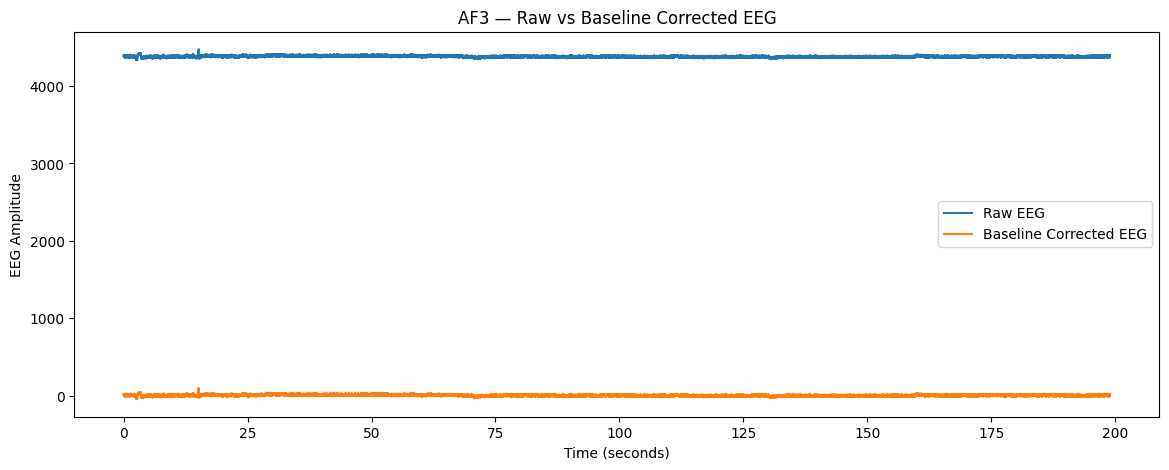

In [49]:
# Visualize baseline correction
time = np.arange(stimulus_trial.shape[0]) / sampling_rate

plt.figure(figsize=(14, 5))

plt.plot(
    time,
    stimulus_trial[:, 0],
    label="Raw EEG"
)

plt.plot(
    time,
    baseline_corrected[:, 0],
    label="Baseline Corrected EEG"
)

plt.xlabel("Time (seconds)")
plt.ylabel("EEG Amplitude")
plt.title("AF3 — Raw vs Baseline Corrected EEG")
plt.legend()

plt.show()

In [50]:
# 50 Hz Notch Filter
notch_freq = 50.0
quality_factor = 30

b_notch, a_notch = iirnotch(
    w0=notch_freq,
    Q=quality_factor,
    fs=sampling_rate
)

notch_filtered_eeg = filtfilt(
    b_notch,
    a_notch,
    baseline_corrected,
    axis=0
)

print("Notch filtered EEG shape:", notch_filtered_eeg.shape)

Notch filtered EEG shape: (25472, 14)


In [51]:
# 1–45 Hz Band-pass
low_cutoff = 1.0
high_cutoff = 45.0

sos = butter(
    N=4,
    Wn=[low_cutoff, high_cutoff],
    btype='bandpass',
    fs=sampling_rate,
    output='sos'
)

clean_eeg = sosfiltfilt(
    sos,
    notch_filtered_eeg,
    axis=0
)

print("Clean EEG shape:", clean_eeg.shape)

Clean EEG shape: (25472, 14)


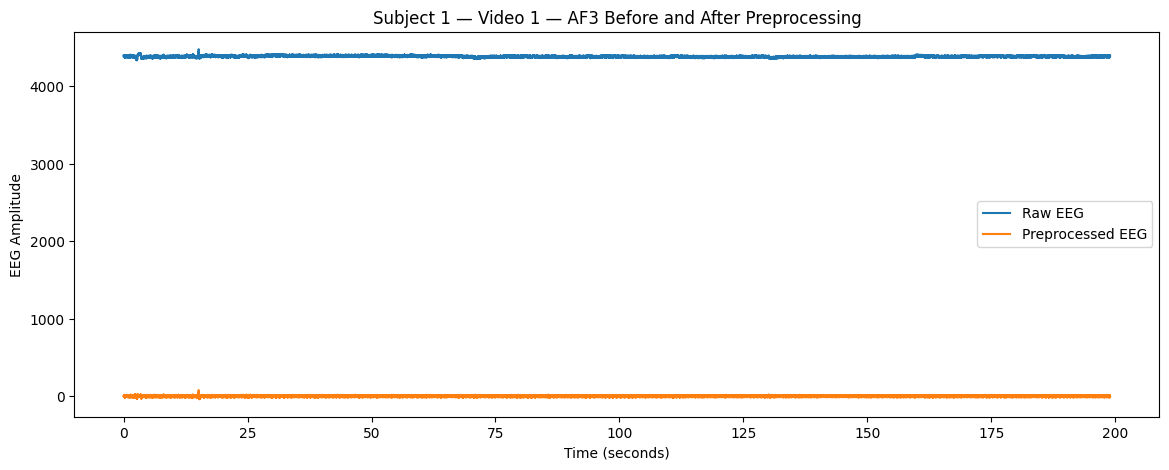

In [52]:
# Compare Raw vs Preprocessed EEG
time = np.arange(stimulus_trial.shape[0]) / sampling_rate

plt.figure(figsize=(14, 5))

plt.plot(
    time,
    stimulus_trial[:, 0],
    label="Raw EEG"
)

plt.plot(
    time,
    clean_eeg[:, 0],
    label="Preprocessed EEG"
)

plt.xlabel("Time (seconds)")
plt.ylabel("EEG Amplitude")
plt.title("Subject 1 — Video 1 — AF3 Before and After Preprocessing")
plt.legend()

plt.show()

In [53]:
# Check All 14 Channels
for i, ch in enumerate(channels):

    signal = clean_eeg[:, i]

    print(
        f"{ch:4s} | "
        f"Min: {np.min(signal):8.2f} | "
        f"Max: {np.max(signal):8.2f} | "
        f"Mean: {np.mean(signal):8.2f} | "
        f"Std: {np.std(signal):8.2f}"
    )

AF3  | Min:   -38.98 | Max:    78.45 | Mean:    -0.00 | Std:     8.05
F7   | Min:   -63.54 | Max:   154.08 | Mean:    -0.00 | Std:     8.84
F3   | Min:  -428.61 | Max:  1116.74 | Mean:     0.02 | Std:    55.49
FC5  | Min:  -476.46 | Max:  1242.62 | Mean:     0.02 | Std:    64.19
T7   | Min:  -592.17 | Max:  1452.42 | Mean:     0.02 | Std:    79.68
P7   | Min:  -162.69 | Max:   351.45 | Mean:     0.01 | Std:    20.36
O1   | Min:  -431.60 | Max:   929.59 | Mean:     0.02 | Std:    52.57
O2   | Min:  -639.04 | Max:  1488.66 | Mean:     0.03 | Std:    78.10
P8   | Min:  -455.77 | Max:  1208.35 | Mean:     0.02 | Std:    61.15
T8   | Min:  -636.38 | Max:  1464.02 | Mean:     0.02 | Std:    83.16
FC6  | Min:  -465.38 | Max:  1025.48 | Mean:     0.03 | Std:    53.31
F4   | Min:  -253.48 | Max:   686.96 | Mean:     0.01 | Std:    33.07
F8   | Min:  -532.60 | Max:  1406.77 | Mean:     0.02 | Std:    70.51
AF4  | Min:  -655.29 | Max:  1600.55 | Mean:     0.03 | Std:    87.54


In [54]:
# Detect Potential Artifacts
artifact_indices = {}

for i, ch in enumerate(channels):

    signal = clean_eeg[:, i]

    mean = np.mean(signal)
    std = np.std(signal)

    indices = np.where(
        np.abs(signal - mean) > 5 * std
    )[0]

    artifact_indices[ch] = indices

    print(
        f"{ch:4s}: "
        f"{len(indices)} extreme samples "
        f"({len(indices) / len(signal) * 100:.2f}%)"
    )

AF3 : 11 extreme samples (0.04%)
F7  : 34 extreme samples (0.13%)
F3  : 45 extreme samples (0.18%)
FC5 : 43 extreme samples (0.17%)
T7  : 39 extreme samples (0.15%)
P7  : 99 extreme samples (0.39%)
O1  : 36 extreme samples (0.14%)
O2  : 40 extreme samples (0.16%)
P8  : 45 extreme samples (0.18%)
T8  : 42 extreme samples (0.16%)
FC6 : 45 extreme samples (0.18%)
F4  : 47 extreme samples (0.18%)
F8  : 44 extreme samples (0.17%)
AF4 : 35 extreme samples (0.14%)


In [55]:
# Find Continuous Artifact Segments
def find_artifact_segments(mask):

    padded = np.concatenate(([False], mask, [False]))

    changes = np.diff(padded.astype(int))

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0] - 1

    return list(zip(starts, ends))

In [56]:
for i, ch in enumerate(channels):

    signal = clean_eeg[:, i]

    mean = np.mean(signal)
    std = np.std(signal)

    mask = np.abs(signal - mean) > 5 * std

    segments = find_artifact_segments(mask)

    if len(segments) > 0:

        durations = [
            (end - start + 1) / sampling_rate
            for start, end in segments
        ]

        print(
            f"{ch:4s}: "
            f"{len(segments)} segments | "
            f"Longest: {max(durations):.4f} sec"
        )

    else:
        print(f"{ch:4s}: No potential artifacts")

AF3 : 2 segments | Longest: 0.0703 sec
F7  : 6 segments | Longest: 0.1328 sec
F3  : 4 segments | Longest: 0.1406 sec
FC5 : 5 segments | Longest: 0.1328 sec
T7  : 9 segments | Longest: 0.1328 sec
P7  : 10 segments | Longest: 0.1172 sec
O1  : 4 segments | Longest: 0.1250 sec
O2  : 11 segments | Longest: 0.1328 sec
P8  : 4 segments | Longest: 0.1406 sec
T8  : 11 segments | Longest: 0.1328 sec
FC6 : 8 segments | Longest: 0.1328 sec
F4  : 5 segments | Longest: 0.1406 sec
F8  : 11 segments | Longest: 0.1328 sec
AF4 : 10 segments | Longest: 0.1328 sec


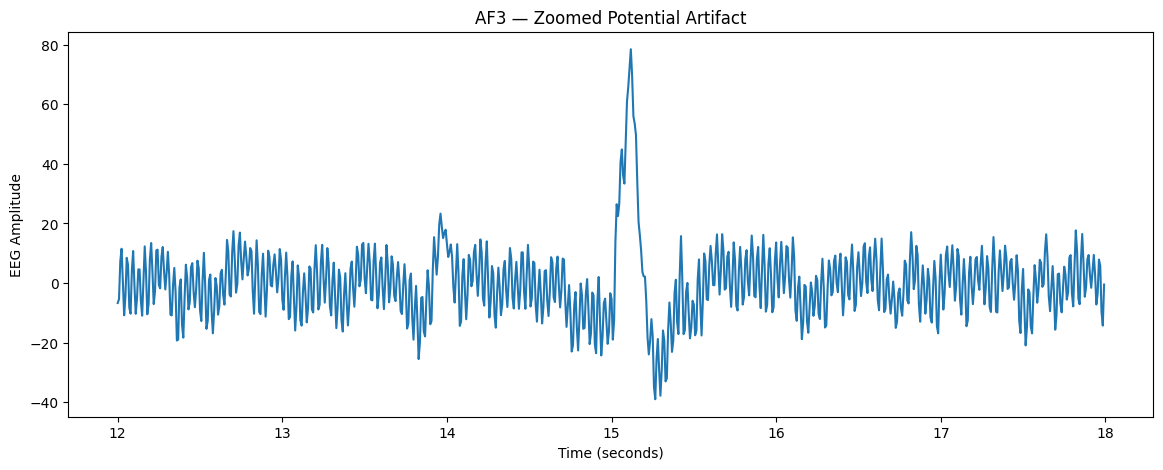

In [57]:
# Zoom Into the AF3 Artifact
start_time = 12
end_time = 18

start_sample = int(start_time * sampling_rate)
end_sample = int(end_time * sampling_rate)

plt.figure(figsize=(14, 5))

plt.plot(
    time[start_sample:end_sample],
    clean_eeg[start_sample:end_sample, 0]
)

plt.xlabel("Time (seconds)")
plt.ylabel("EEG Amplitude")
plt.title("AF3 — Zoomed Potential Artifact")

plt.show()

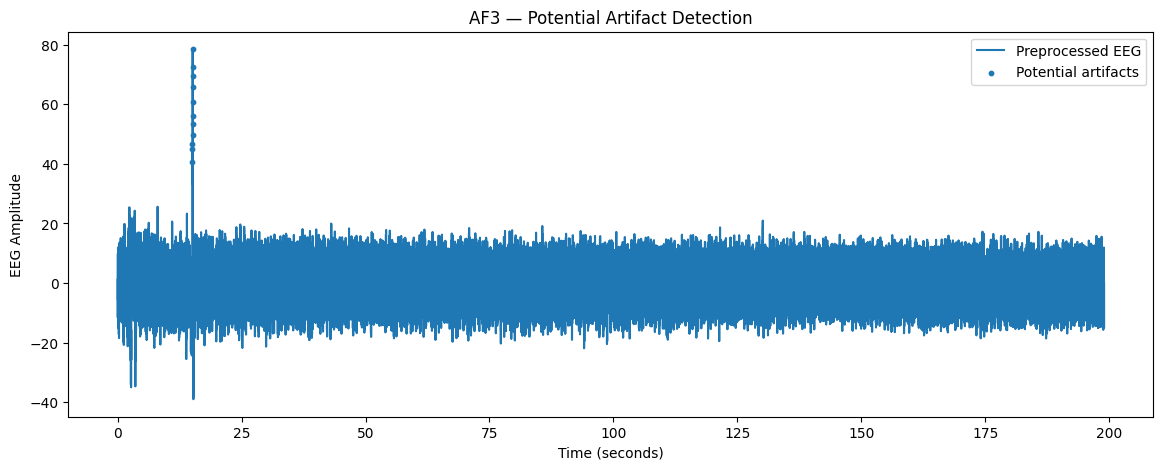

In [58]:
# Mark Potential Artifacts on the Signal
signal = clean_eeg[:, 0]

mean = np.mean(signal)
std = np.std(signal)

artifact_mask = np.abs(signal - mean) > 5 * std

plt.figure(figsize=(14, 5))

plt.plot(
    time,
    signal,
    label="Preprocessed EEG"
)

plt.scatter(
    time[artifact_mask],
    signal[artifact_mask],
    s=10,
    label="Potential artifacts"
)

plt.xlabel("Time (seconds)")
plt.ylabel("EEG Amplitude")
plt.title("AF3 — Potential Artifact Detection")

plt.legend()
plt.show()

In [59]:
subject1 = data[0, 0]

valence_check = subject1['ScoreValence'].item().flatten()
arousal_check = subject1['ScoreArousal'].item().flatten()
dominance_check = subject1['ScoreDominance'].item().flatten()

print("Subject 1, Video 1:")
print("Valence:", int(valence_check[0]))
print("Arousal:", int(arousal_check[0]))
print("Dominance:", int(dominance_check[0]))

Subject 1, Video 1:
Valence: 4
Arousal: 3
Dominance: 2


In [60]:
trial1_processed = {
    'Subject': 1,
    'Video': 1,
    'Valence': int(valence_check[0]),
    'Arousal': int(arousal_check[0]),
    'Dominance': int(dominance_check[0]),
    'EEG': clean_eeg
}

print("Subject:", trial1_processed['Subject'])
print("Video:", trial1_processed['Video'])
print("Valence:", trial1_processed['Valence'])
print("Arousal:", trial1_processed['Arousal'])
print("Dominance:", trial1_processed['Dominance'])
print("EEG shape:", trial1_processed['EEG'].shape)

Subject: 1
Video: 1
Valence: 4
Arousal: 3
Dominance: 2
EEG shape: (25472, 14)


### Segmentation

In [61]:
# Create a segmentation function
def segment_eeg(eeg, sampling_rate=128, window_seconds=5):
    """
    Divide EEG into fixed-length non-overlapping windows.

    Parameters:
        eeg: EEG array of shape (samples, channels)
        sampling_rate: EEG sampling rate
        window_seconds: window duration in seconds

    Returns:
        segments: array of shape (num_segments, window_samples, channels)
    """

    window_samples = int(sampling_rate * window_seconds)

    n_samples = eeg.shape[0]
    n_channels = eeg.shape[1]

    n_segments = n_samples // window_samples

    segments = []

    for i in range(n_segments):
        start = i * window_samples
        end = start + window_samples

        segment = eeg[start:end, :]

        segments.append(segment)

    return np.array(segments)

In [62]:
# Test it on Subject 1, Video 1
clean_eeg

array([[ 1.05808372e+00,  5.92166837e-01, -2.01472160e-01, ...,
         4.01719607e-01, -3.01184449e+00, -1.50923120e+01],
       [-1.15890730e+01, -8.16440668e+00,  3.69574203e+01, ...,
         1.49626259e+01,  4.97725587e+01,  7.40206653e+01],
       [-7.71463322e+00, -9.39821364e+00,  1.70465629e+01, ...,
         9.66198240e+00,  7.25494662e+00,  2.94168101e+01],
       ...,
       [-1.45398401e+01, -4.01691970e+00,  7.58008657e+01, ...,
         3.14972856e+01,  9.32566197e+01,  1.08041597e+02],
       [-1.49041233e+01, -6.19945945e+00,  5.64162222e+01, ...,
         2.38353443e+01,  6.98059936e+01,  9.17359798e+01],
       [-9.87313404e-02,  2.54399504e+00,  1.36392888e+01, ...,
         7.06751307e+00,  1.59459807e+01,  1.35812898e+01]])

In [63]:
segments = segment_eeg(
    clean_eeg,
    sampling_rate=128,
    window_seconds=5
)

print("Segmented EEG shape:", segments.shape)

Segmented EEG shape: (39, 640, 14)


In [64]:
# Check one segment
print("Number of segments:", len(segments))
print("One segment shape:", segments[0].shape)

Number of segments: 39
One segment shape: (640, 14)


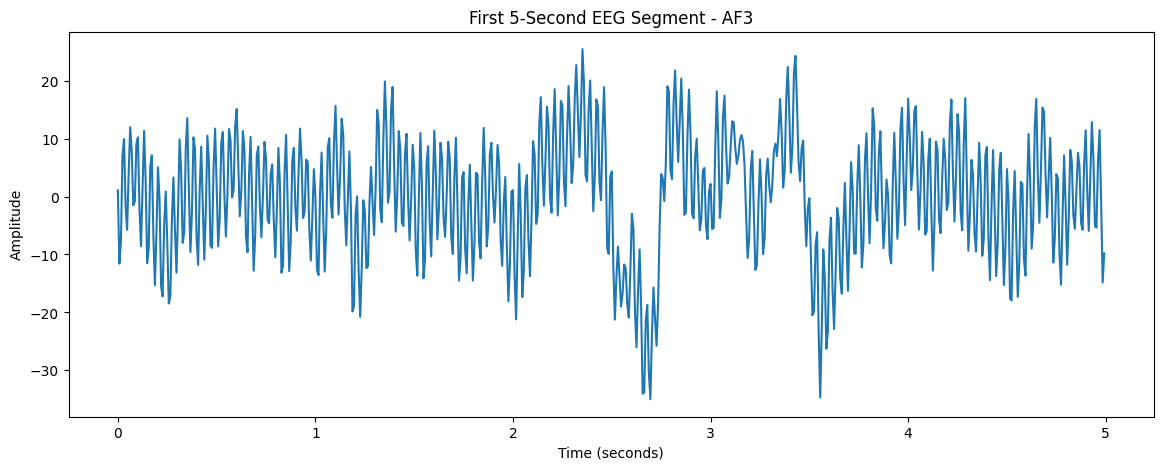

In [65]:
# Visualize the first segment
segment = segments[0]

time_segment = np.arange(segment.shape[0]) / 128

plt.figure(figsize=(14, 5))

plt.plot(
    time_segment,
    segment[:, 0]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("First 5-Second EEG Segment - AF3")

plt.show()

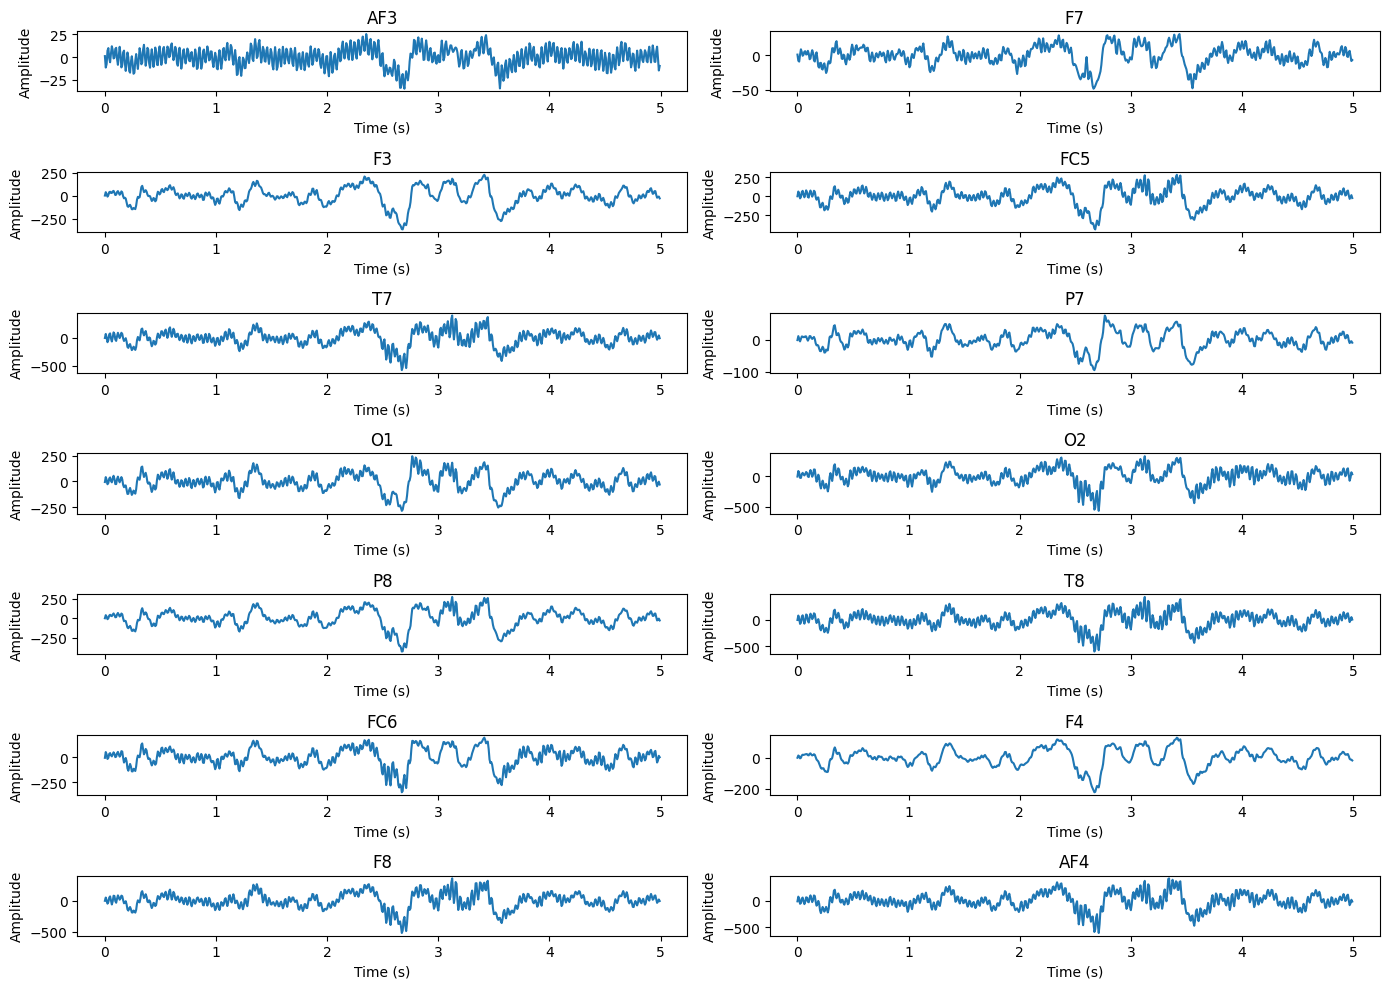

In [66]:
# Check all 14 channels
plt.figure(figsize=(14, 10))

for i in range(14):
    plt.subplot(7, 2, i + 1)

    plt.plot(
        time_segment,
        segments[0, :, i]
    )

    plt.title(channels[i])
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [67]:
# Create the segment records
segment_records = []

for i, segment in enumerate(segments):

    segment_records.append({
        'Subject': 1,
        'Video': 1,
        'Segment': i + 1,
        'Valence': int(valence_check[0]),
        'Arousal': int(arousal_check[0]),
        'Dominance': int(dominance_check[0]),
        'EEG': segment
    })

print("Number of segment records:", len(segment_records))

Number of segment records: 39


In [68]:
# Check one record
print("Subject:", segment_records[0]['Subject'])
print("Video:", segment_records[0]['Video'])
print("Segment:", segment_records[0]['Segment'])
print("Valence:", segment_records[0]['Valence'])
print("Arousal:", segment_records[0]['Arousal'])
print("Dominance:", segment_records[0]['Dominance'])
print("EEG shape:", segment_records[0]['EEG'].shape)

Subject: 1
Video: 1
Segment: 1
Valence: 4
Arousal: 3
Dominance: 2
EEG shape: (640, 14)


In [69]:
# Create the complete segmentation function
def segment_trial(eeg, sampling_rate=128, window_seconds=5):
    window_samples = int(sampling_rate * window_seconds)

    n_samples = eeg.shape[0]
    n_segments = n_samples // window_samples

    segments = []

    for i in range(n_segments):
        start = i * window_samples
        end = start + window_samples

        segments.append(eeg[start:end])

    return np.array(segments)

In [70]:
# Process all subjects and videos
all_segments = []
all_segment_labels = []

for s in range(n_subjects):

    subject = data[0, s]

    # Extract labels for this subject
    valence = subject['ScoreValence'].item().flatten()
    arousal = subject['ScoreArousal'].item().flatten()
    dominance = subject['ScoreDominance'].item().flatten()

    # EEG structure
    eeg_struct = subject['EEG'].item()

    baseline_data = eeg_struct['baseline'].item()
    stimuli_data = eeg_struct['stimuli'].item()

    for v in range(n_videos):

        # Get baseline and stimulus EEG
        baseline_trial = baseline_data[v, 0]
        stimulus_trial = stimuli_data[v, 0]

        # -----------------------------
        # 1. Baseline correction
        # -----------------------------
        baseline_mean = np.mean(baseline_trial, axis=0)

        baseline_corrected = (
            stimulus_trial - baseline_mean
        )

        # -----------------------------
        # 2. 50 Hz notch filter
        # -----------------------------
        notch_filtered_eeg = filtfilt(
            b_notch,
            a_notch,
            baseline_corrected,
            axis=0
        )

        # -----------------------------
        # 3. 1–45 Hz band-pass
        # -----------------------------
        clean_eeg = sosfiltfilt(
            sos,
            notch_filtered_eeg,
            axis=0
        )

        # -----------------------------
        # 4. Segment into 5-sec windows
        # -----------------------------
        segments = segment_trial(
            clean_eeg,
            sampling_rate=128,
            window_seconds=5
        )

        # -----------------------------
        # 5. Store segments + labels
        # -----------------------------
        for segment_id, segment in enumerate(segments):

            all_segments.append(segment)

            all_segment_labels.append([
                s + 1,                    # Subject
                v + 1,                    # Video
                segment_id + 1,            # Segment
                int(valence[v]),           # Valence
                int(arousal[v]),           # Arousal
                int(dominance[v])          # Dominance
            ])

    print(f"Subject {s+1}/{n_subjects} processed")

Subject 1/23 processed
Subject 2/23 processed
Subject 3/23 processed
Subject 4/23 processed
Subject 5/23 processed
Subject 6/23 processed
Subject 7/23 processed
Subject 8/23 processed
Subject 9/23 processed
Subject 10/23 processed
Subject 11/23 processed
Subject 12/23 processed
Subject 13/23 processed
Subject 14/23 processed
Subject 15/23 processed
Subject 16/23 processed
Subject 17/23 processed
Subject 18/23 processed
Subject 19/23 processed
Subject 20/23 processed
Subject 21/23 processed
Subject 22/23 processed
Subject 23/23 processed


In [71]:
# Convert to NumPy arrays
all_segments = np.array(all_segments)

all_segment_labels = np.array(
    all_segment_labels
)

print("All segments shape:", all_segments.shape)
print("All labels shape:", all_segment_labels.shape)

All segments shape: (17020, 640, 14)
All labels shape: (17020, 6)


In [72]:
# Verify that labels match the EEG segments
print("Total EEG segments:", len(all_segments))
print("Total label records:", len(all_segment_labels))

print("\nFirst 5 label records:")
print(all_segment_labels[:5])

Total EEG segments: 17020
Total label records: 17020

First 5 label records:
[[1 1 1 4 3 2]
 [1 1 2 4 3 2]
 [1 1 3 4 3 2]
 [1 1 4 4 3 2]
 [1 1 5 4 3 2]]


In [73]:
print("\nFirst segment shape:")
print(all_segments[0].shape)


First segment shape:
(640, 14)


In [74]:
# Check Subject 1 / Video 1
mask = (
    (all_segment_labels[:, 0] == 1) &
    (all_segment_labels[:, 1] == 1)
)

subject1_video1_segments = all_segments[mask]

subject1_video1_labels = all_segment_labels[mask]

print("Subject 1, Video 1 segments:",
      len(subject1_video1_segments))

print("\nLabels:")
print(subject1_video1_labels[:5])

Subject 1, Video 1 segments: 39

Labels:
[[1 1 1 4 3 2]
 [1 1 2 4 3 2]
 [1 1 3 4 3 2]
 [1 1 4 4 3 2]
 [1 1 5 4 3 2]]


### Emotion Label Preparation

In [75]:
# Create clean label arrays
valence_labels = all_segment_labels[:, 3].astype(np.int64)
arousal_labels = all_segment_labels[:, 4].astype(np.int64)
dominance_labels = all_segment_labels[:, 5].astype(np.int64)

print("Valence shape:", valence_labels.shape)
print("Arousal shape:", arousal_labels.shape)
print("Dominance shape:", dominance_labels.shape)

Valence shape: (17020,)
Arousal shape: (17020,)
Dominance shape: (17020,)


In [76]:
# Verify the labels
print("Valence classes:",
      np.unique(valence_labels))

print("Arousal classes:",
      np.unique(arousal_labels))

print("Dominance classes:",
      np.unique(dominance_labels))

Valence classes: [1 2 3 4 5]
Arousal classes: [1 2 3 4 5]
Dominance classes: [1 2 3 4 5]


In [77]:
# Convert labels to 0–4
valence_class = valence_labels - 1
arousal_class = arousal_labels - 1
dominance_class = dominance_labels - 1

print("Valence classes:", np.unique(valence_class))
print("Arousal classes:", np.unique(arousal_class))
print("Dominance classes:", np.unique(dominance_class))

Valence classes: [0 1 2 3 4]
Arousal classes: [0 1 2 3 4]
Dominance classes: [0 1 2 3 4]


In [78]:
# Check one sample
sample = 0

print("Subject:",
      all_segment_labels[sample, 0])

print("Video:",
      all_segment_labels[sample, 1])

print("Segment:",
      all_segment_labels[sample, 2])

print("Original Valence:",
      valence_labels[sample])

print("Model Valence Class:",
      valence_class[sample])

print("Original Arousal:",
      arousal_labels[sample])

print("Model Arousal Class:",
      arousal_class[sample])

print("Original Dominance:",
      dominance_labels[sample])

print("Model Dominance Class:",
      dominance_class[sample])

Subject: 1
Video: 1
Segment: 1
Original Valence: 4
Model Valence Class: 3
Original Arousal: 3
Model Arousal Class: 2
Original Dominance: 2
Model Dominance Class: 1


### Subject-Level Train / Validation / Test Split

In [79]:
# Get the subject IDs
subjects = all_segment_labels[:, 0].astype(int)

unique_subjects = np.unique(subjects)

print("Number of subjects:", len(unique_subjects))
print("Subject IDs:", unique_subjects)

Number of subjects: 23
Subject IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


In [80]:
# Create the split
from sklearn.model_selection import train_test_split

# Get unique subjects
unique_subjects = np.unique(subjects)

# Fixed seed for reproducibility
random_state = 42

# 15 train, 8 remaining
train_subjects, temp_subjects = train_test_split(
    unique_subjects,
    test_size=8,
    random_state=random_state,
    shuffle=True
)

# Split remaining 8 into 4 validation + 4 test
val_subjects, test_subjects = train_test_split(
    temp_subjects,
    test_size=4,
    random_state=random_state,
    shuffle=True
)

print("Training subjects:", np.sort(train_subjects))
print("Validation subjects:", np.sort(val_subjects))
print("Test subjects:", np.sort(test_subjects))

print("\nNumber of training subjects:", len(train_subjects))
print("Number of validation subjects:", len(val_subjects))
print("Number of test subjects:", len(test_subjects))

Training subjects: [ 3  4  5  6  7  8 11 12 15 17 19 20 21 22 23]
Validation subjects: [ 1  2  9 18]
Test subjects: [10 13 14 16]

Number of training subjects: 15
Number of validation subjects: 4
Number of test subjects: 4


In [81]:
# Create masks
train_mask = np.isin(
    subjects,
    train_subjects
)

val_mask = np.isin(
    subjects,
    val_subjects
)

test_mask = np.isin(
    subjects,
    test_subjects
)

print("Training segments:", np.sum(train_mask))
print("Validation segments:", np.sum(val_mask))
print("Test segments:", np.sum(test_mask))

print(
    "\nTotal:",
    np.sum(train_mask) +
    np.sum(val_mask) +
    np.sum(test_mask)
)

Training segments: 11100
Validation segments: 2960
Test segments: 2960

Total: 17020


In [82]:
# Create EEG datasets
X_train = all_segments[train_mask]
X_val = all_segments[val_mask]
X_test = all_segments[test_mask]

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

X_train: (11100, 640, 14)
X_val:   (2960, 640, 14)
X_test:  (2960, 640, 14)


In [83]:
# Create the three targets
y_valence_train = valence_class[train_mask]
y_valence_val = valence_class[val_mask]
y_valence_test = valence_class[test_mask]

y_arousal_train = arousal_class[train_mask]
y_arousal_val = arousal_class[val_mask]
y_arousal_test = arousal_class[test_mask]

y_dominance_train = dominance_class[train_mask]
y_dominance_val = dominance_class[val_mask]
y_dominance_test = dominance_class[test_mask]

In [84]:
# Verify the split
print("TRAIN")
print("X:", X_train.shape)
print("Valence:", y_valence_train.shape)
print("Arousal:", y_arousal_train.shape)
print("Dominance:", y_dominance_train.shape)

print("\nVALIDATION")
print("X:", X_val.shape)
print("Valence:", y_valence_val.shape)
print("Arousal:", y_arousal_val.shape)
print("Dominance:", y_dominance_val.shape)

print("\nTEST")
print("X:", X_test.shape)
print("Valence:", y_valence_test.shape)
print("Arousal:", y_arousal_test.shape)
print("Dominance:", y_dominance_test.shape)

TRAIN
X: (11100, 640, 14)
Valence: (11100,)
Arousal: (11100,)
Dominance: (11100,)

VALIDATION
X: (2960, 640, 14)
Valence: (2960,)
Arousal: (2960,)
Dominance: (2960,)

TEST
X: (2960, 640, 14)
Valence: (2960,)
Arousal: (2960,)
Dominance: (2960,)


In [85]:
# no subject leakage
print("Train ∩ Validation:",
      set(train_subjects) & set(val_subjects))

print("Train ∩ Test:",
      set(train_subjects) & set(test_subjects))

print("Validation ∩ Test:",
      set(val_subjects) & set(test_subjects))

Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()


In [86]:
# Check the actual subject distribution
print("\nTRAIN subjects:")
print(np.sort(train_subjects))

print("\nVALIDATION subjects:")
print(np.sort(val_subjects))

print("\nTEST subjects:")
print(np.sort(test_subjects))


TRAIN subjects:
[ 3  4  5  6  7  8 11 12 15 17 19 20 21 22 23]

VALIDATION subjects:
[ 1  2  9 18]

TEST subjects:
[10 13 14 16]


### EEG Normalization

In [87]:
# Calculate channel-wise mean and standard deviation
train_mean = np.mean(
    X_train,
    axis=(0, 1)
)

train_std = np.std(
    X_train,
    axis=(0, 1)
)

print("Training channel means:")
print(train_mean)

print("\nTraining channel standard deviations:")
print(train_std)

Training channel means:
[-0.00646813 -0.00556522 -0.00568948 -0.00572849 -0.00917829 -0.00026519
 -0.00014117 -0.00181956 -0.00108262 -0.0085473  -0.00625708 -0.00589128
 -0.00674714 -0.00215217]

Training channel standard deviations:
[114.02576926 109.90096895  97.40871546  95.51183269 123.00709273
  18.37668169  53.00352305  57.75475296  45.85849173 122.61081414
 120.34715398 125.10745675 126.46492546 123.89283312]


In [88]:
# Standardize the three datasets
X_train_norm = (
    X_train - train_mean
) / train_std

X_val_norm = (
    X_val - train_mean
) / train_std

X_test_norm = (
    X_test - train_mean
) / train_std

In [89]:
# Verify normalization
print("Training normalized mean:")
print(np.mean(X_train_norm, axis=(0, 1)))

print("\nTraining normalized std:")
print(np.std(X_train_norm, axis=(0, 1)))

Training normalized mean:
[ 4.36708821e-20  1.57779547e-18  6.44473604e-18  1.79976486e-18
 -1.00588712e-18 -1.24129623e-18  9.27893234e-18  8.68709665e-19
  3.17433200e-18  1.20609756e-17 -2.27964404e-18 -5.80683055e-19
 -4.63654542e-19 -1.80261797e-19]

Training normalized std:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [90]:
# Check validation and test
print("Validation overall mean:",
      np.mean(X_val_norm))

print("Validation overall std:",
      np.std(X_val_norm))

print("\nTest overall mean:",
      np.mean(X_test_norm))

print("Test overall std:",
      np.std(X_test_norm))

Validation overall mean: -1.4650756406318007e-05
Validation overall std: 0.7348802224616355

Test overall mean: 5.920065558276303e-05
Test overall std: 0.6033817275250164


In [91]:
# Check for numerical problems
print("NaN in training:",
      np.isnan(X_train_norm).sum())

print("NaN in validation:",
      np.isnan(X_val_norm).sum())

print("NaN in test:",
      np.isnan(X_test_norm).sum())

print("Inf in training:",
      np.isinf(X_train_norm).sum())

print("Inf in validation:",
      np.isinf(X_val_norm).sum())

print("Inf in test:",
      np.isinf(X_test_norm).sum())

NaN in training: 0
NaN in validation: 0
NaN in test: 0
Inf in training: 0
Inf in validation: 0
Inf in test: 0


### EEG Feature Extraction

In [92]:
# Convert normalized EEG to float32
X_train_norm = X_train_norm.astype(np.float32)
X_val_norm = X_val_norm.astype(np.float32)
X_test_norm = X_test_norm.astype(np.float32)

print("Training dtype:", X_train_norm.dtype)
print("Validation dtype:", X_val_norm.dtype)
print("Test dtype:", X_test_norm.dtype)

print("Training shape:", X_train_norm.shape)
print("Validation shape:", X_val_norm.shape)
print("Test shape:", X_test_norm.shape)

Training dtype: float32
Validation dtype: float32
Test dtype: float32
Training shape: (11100, 640, 14)
Validation shape: (2960, 640, 14)
Test shape: (2960, 640, 14)


In [93]:
# Import the feature extraction tools
from scipy.signal import welch

In [94]:
# Define the feature extraction function
import numpy as np
from scipy.signal import welch

sampling_rate = 128

EEG_BANDS = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "gamma": (30, 45)
}


def extract_eeg_features(X, batch_size=256):
    """
    Extract 196 handcrafted features per EEG segment.

    Input:
        X: array shaped (segments, 640, 14)

    Output:
        Feature matrix shaped (segments, 196)
    """

    all_features = []

    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size]

        # ----------------------------------
        # A. Time-domain features
        # ----------------------------------

        mean_features = np.mean(batch, axis=1)

        std_features = np.std(batch, axis=1)

        rms_features = np.sqrt(
            np.mean(batch ** 2, axis=1)
        )

        line_length_features = np.mean(
            np.abs(np.diff(batch, axis=1)),
            axis=1
        )

        time_features = np.stack(
            [
                mean_features,
                std_features,
                rms_features,
                line_length_features
            ],
            axis=2
        )

        # Shape: (batch, 14 channels, 4 features)

        # ----------------------------------
        # B. Frequency-domain features
        # ----------------------------------

        frequencies, psd = welch(
            batch,
            fs=sampling_rate,
            nperseg=256,
            axis=1
        )

        # PSD shape: (batch, frequencies, channels)

        absolute_band_powers = []

        for band_name, (low, high) in EEG_BANDS.items():

            # Include the lower boundary.
            # Exclude the upper boundary to avoid
            # double-counting shared band boundaries.
            band_mask = (
                (frequencies >= low) &
                (frequencies < high)
            )

            band_power = np.trapezoid(
                psd[:, band_mask, :],
                x=frequencies[band_mask],
                axis=1
            )

            absolute_band_powers.append(band_power)

        # Shape: (batch, 5 bands, 14 channels)
        absolute_band_powers = np.stack(
            absolute_band_powers,
            axis=1
        )

        # Convert absolute power to log scale.
        log_band_powers = np.log10(
            np.maximum(absolute_band_powers, 1e-12)
        )

        # Relative power: each band's share of total power.
        total_band_power = np.sum(
            absolute_band_powers,
            axis=1,
            keepdims=True
        )

        relative_band_powers = (
            absolute_band_powers /
            np.maximum(total_band_power, 1e-12)
        )

        # Reorder to (batch, channels, features)
        log_band_powers = np.transpose(
            log_band_powers,
            (0, 2, 1)
        )

        relative_band_powers = np.transpose(
            relative_band_powers,
            (0, 2, 1)
        )

        # ----------------------------------
        # C. Combine features
        # ----------------------------------

        features = np.concatenate(
            [
                time_features,
                log_band_powers,
                relative_band_powers
            ],
            axis=2
        )

        # Shape: (batch, 14 channels, 14 features)

        # Flatten channels and features.
        features = features.reshape(
            len(batch), -1
        )

        all_features.append(
            features.astype(np.float32)
        )

        print(
            f"Processed {min(start + batch_size, len(X))}"
            f"/{len(X)} segments",
            end="\r"
        )

    print()

    return np.concatenate(all_features, axis=0)

In [95]:
# Extract features for all three splits
X_train_features = extract_eeg_features(X_train_norm)

X_val_features = extract_eeg_features(X_val_norm)

X_test_features = extract_eeg_features(X_test_norm)

Processed 11100/11100 segments
Processed 2960/2960 segments
Processed 2960/2960 segments


In [96]:
# Verify the output
print("Training features:", X_train_features.shape)
print("Validation features:", X_val_features.shape)
print("Test features:", X_test_features.shape)

print("\nFeature dtype:", X_train_features.dtype)

print("\nExpected features per segment:", 196)

Training features: (11100, 196)
Validation features: (2960, 196)
Test features: (2960, 196)

Feature dtype: float32

Expected features per segment: 196


In [97]:
# Check for invalid feature values
print("Training NaN:", np.isnan(X_train_features).sum())
print("Validation NaN:", np.isnan(X_val_features).sum())
print("Test NaN:", np.isnan(X_test_features).sum())

print("Training Inf:", np.isinf(X_train_features).sum())
print("Validation Inf:", np.isinf(X_val_features).sum())
print("Test Inf:", np.isinf(X_test_features).sum())

Training NaN: 0
Validation NaN: 0
Test NaN: 0
Training Inf: 0
Validation Inf: 0
Test Inf: 0


In [98]:
# Inspect a feature vector
print("First segment feature vector:")
print(X_train_features[0])

print("\nNumber of features:",
      len(X_train_features[0]))

First segment feature vector:
[-1.59338029e-04  3.31526011e-01  3.31526130e-01  5.47036715e-02
 -1.07157445e+00 -1.59511697e+00 -2.69517350e+00 -2.71986699e+00
 -3.27084446e+00  7.39575088e-01  2.21533686e-01  1.75947510e-02
  1.66222434e-02  4.67425259e-03 -2.33906176e-04  2.11526826e-01
  2.11527094e-01  4.80358750e-02 -1.53132915e+00 -1.99854112e+00
 -2.92385578e+00 -2.76744127e+00 -3.14348435e+00  6.83053017e-01
  2.32939139e-01  2.76648141e-02  3.96590456e-02  1.66839659e-02
 -8.36971332e-04  9.06240717e-02  9.06279385e-02  3.73955928e-02
 -2.34630609e+00 -2.73641348e+00 -3.34305954e+00 -3.01608539e+00
 -3.37909365e+00  5.51066458e-01  2.24438086e-01  5.55201434e-02
  1.17875844e-01  5.10994829e-02 -2.24971352e-03  8.20664540e-02
  8.20973068e-02  3.56978700e-02 -2.43591380e+00 -2.85221100e+00
 -3.65654540e+00 -3.12248516e+00 -3.43312025e+00  5.71411967e-01
  2.19105020e-01  3.43809426e-02  1.17592081e-01  5.75099662e-02
 -5.64645627e-04  1.55203864e-01  1.55204847e-01  1.26463935

### Scale features for classical machine learning

In [99]:
# Fit the scaler
from sklearn.preprocessing import StandardScaler

feature_scaler = StandardScaler()

X_train_scaled = feature_scaler.fit_transform(
    X_train_features
)

X_val_scaled = feature_scaler.transform(
    X_val_features
)

X_test_scaled = feature_scaler.transform(
    X_test_features
)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Training: (11100, 196)
Validation: (2960, 196)
Test: (2960, 196)


In [100]:
# Verify scaling
print("Training feature means (first 10):")
print(np.mean(X_train_scaled, axis=0)[:10])

print("\nTraining feature stds (first 10):")
print(np.std(X_train_scaled, axis=0)[:10])

print("\nNaN counts:")
print(
    np.isnan(X_train_scaled).sum(),
    np.isnan(X_val_scaled).sum(),
    np.isnan(X_test_scaled).sum()
)

print("\nInfinite counts:")
print(
    np.isinf(X_train_scaled).sum(),
    np.isinf(X_val_scaled).sum(),
    np.isinf(X_test_scaled).sum()
)

Training feature means (first 10):
[-4.2824060e-09 -1.3759812e-07  4.0633186e-08 -1.7608608e-07
 -2.5295594e-07  2.1753010e-08 -4.3539583e-08  2.0050520e-07
  3.6452803e-08  8.1150915e-08]

Training feature stds (first 10):
[0.9999946  1.0000011  1.0000006  1.0000007  0.99999964 0.99999887
 0.99999845 0.9999995  1.0000004  0.9999998 ]

NaN counts:
0 0 0

Infinite counts:
0 0 0


In [101]:
# Prepare the three prediction tasks
# Original model classes are already encoded as 0–4.

targets = {
    "Valence": (
        y_valence_train,
        y_valence_val,
        y_valence_test
    ),
    "Arousal": (
        y_arousal_train,
        y_arousal_val,
        y_arousal_test
    ),
    "Dominance": (
        y_dominance_train,
        y_dominance_val,
        y_dominance_test
    )
}

for name, (ytr, yv, yte) in targets.items():
    print(
        name,
        "| Train:", len(ytr),
        "| Validation:", len(yv),
        "| Test:", len(yte)
    )

Valence | Train: 11100 | Validation: 2960 | Test: 2960
Arousal | Train: 11100 | Validation: 2960 | Test: 2960
Dominance | Train: 11100 | Validation: 2960 | Test: 2960


In [102]:
# Check class counts in each split
for name, (ytr, yv, yte) in targets.items():
    print(f"\n{name}")

    for split_name, y in [
        ("Train", ytr),
        ("Validation", yv),
        ("Test", yte)
    ]:
        classes, counts = np.unique(
            y, return_counts=True
        )

        print(
            f"{split_name}:",
            dict(zip(classes.tolist(), counts.tolist()))
        )


Valence
Train: {0: 2223, 1: 2129, 2: 2421, 3: 2624, 4: 1703}
Validation: {0: 583, 1: 668, 2: 526, 3: 741, 4: 442}
Test: {0: 610, 1: 448, 2: 421, 3: 826, 4: 655}

Arousal
Train: {0: 446, 1: 2084, 2: 3372, 3: 4016, 4: 1182}
Validation: {0: 34, 1: 487, 2: 824, 3: 1029, 4: 586}
Test: {0: 215, 1: 689, 2: 711, 3: 916, 4: 429}

Dominance
Train: {0: 346, 1: 1792, 2: 3245, 3: 3817, 4: 1900}
Validation: {0: 26, 1: 474, 2: 596, 3: 1310, 4: 554}
Test: {0: 79, 1: 699, 2: 620, 3: 991, 4: 571}


### Train Classical ML Baseline Models

In [103]:
# Import libraries
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import numpy as np
import time

In [104]:
# Define the models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "SVM RBF": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    )
}

In [105]:
# Train and validate all nine model-task combinations
results = []
trained_models = {}

for target_name, (y_train, y_val, y_test) in targets.items():

    print(f"\n{'=' * 55}")
    print(f"TARGET: {target_name}")
    print('=' * 55)

    for model_name, model_template in models.items():

        # Create a fresh model for each target
        import sklearn.base
        model = sklearn.base.clone(model_template)

        start_time = time.time()

        model.fit(X_train_scaled, y_train)

        train_seconds = time.time() - start_time

        val_predictions = model.predict(X_val_scaled)

        accuracy = accuracy_score(y_val, val_predictions)
        macro_f1 = f1_score(
            y_val,
            val_predictions,
            average="macro",
            zero_division=0
        )
        weighted_f1 = f1_score(
            y_val,
            val_predictions,
            average="weighted",
            zero_division=0
        )
        balanced_acc = balanced_accuracy_score(
            y_val,
            val_predictions
        )

        results.append({
            "Target": target_name,
            "Model": model_name,
            "Validation Accuracy": accuracy,
            "Validation Macro-F1": macro_f1,
            "Validation Weighted-F1": weighted_f1,
            "Validation Balanced Accuracy": balanced_acc,
            "Training Seconds": train_seconds
        })

        trained_models[(target_name, model_name)] = model

        print(
            f"{model_name:22s} | "
            f"Accuracy={accuracy:.4f} | "
            f"Macro-F1={macro_f1:.4f} | "
            f"Balanced Acc={balanced_acc:.4f} | "
            f"Time={train_seconds:.1f}s"
        )

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["Target", "Validation Macro-F1"],
    ascending=[True, False]
).reset_index(drop=True)

print("\nVALIDATION RESULTS")
display(results_df.round(4))


TARGET: Valence
Logistic Regression    | Accuracy=0.2932 | Macro-F1=0.2840 | Balanced Acc=0.2868 | Time=5.4s
Random Forest          | Accuracy=0.3098 | Macro-F1=0.2705 | Balanced Acc=0.2945 | Time=10.1s
SVM RBF                | Accuracy=0.2834 | Macro-F1=0.2553 | Balanced Acc=0.2765 | Time=11.8s

TARGET: Arousal
Logistic Regression    | Accuracy=0.2176 | Macro-F1=0.1994 | Balanced Acc=0.3503 | Time=6.0s
Random Forest          | Accuracy=0.3020 | Macro-F1=0.1823 | Balanced Acc=0.2030 | Time=8.7s
SVM RBF                | Accuracy=0.2250 | Macro-F1=0.2078 | Balanced Acc=0.3107 | Time=22.9s

TARGET: Dominance
Logistic Regression    | Accuracy=0.2470 | Macro-F1=0.1819 | Balanced Acc=0.1726 | Time=4.8s
Random Forest          | Accuracy=0.3385 | Macro-F1=0.1698 | Balanced Acc=0.1896 | Time=12.2s
SVM RBF                | Accuracy=0.2767 | Macro-F1=0.2006 | Balanced Acc=0.2133 | Time=37.0s

VALIDATION RESULTS


,Target,Model,Validation Accuracy,Validation Macro-F1,Validation Weighted-F1,Validation Balanced Accuracy,Training Seconds
0,Arousal,SVM RBF,0.2250,0.2078,0.2350,0.3107,22.9186
1,Arousal,Logistic Regression,0.2176,0.1994,0.2374,0.3503,6.0016
2,Arousal,Random Forest,0.3020,0.1823,0.2564,0.2030,8.6528
3,Dominance,SVM RBF,0.2767,0.2006,0.2911,0.2133,37.0432
4,Dominance,Logistic Regression,0.2470,0.1819,0.2784,0.1726,4.7822
5,Dominance,Random Forest,0.3385,0.1698,0.3005,0.1896,12.2167
6,Valence,Logistic Regression,0.2932,0.2840,0.2878,0.2868,5.3883
7,Valence,Random Forest,0.3098,0.2705,0.2897,0.2945,10.0696
8,Valence,SVM RBF,0.2834,0.2553,0.2657,0.2765,11.8174


In [106]:
# Show the best model for each target
best_models = {}

for target_name in targets:

    target_results = results_df[
        results_df["Target"] == target_name
    ]

    best_row = target_results.iloc[0]
    best_model_name = best_row["Model"]

    best_models[target_name] = trained_models[
        (target_name, best_model_name)
    ]

    print(
        f"{target_name}: {best_model_name} | "
        f"Validation Macro-F1 = "
        f"{best_row['Validation Macro-F1']:.4f}"
    )

Valence: Logistic Regression | Validation Macro-F1 = 0.2840
Arousal: SVM RBF | Validation Macro-F1 = 0.2078
Dominance: SVM RBF | Validation Macro-F1 = 0.2006


In [107]:
# Evaluate the selected models on the test set
test_results = []
test_predictions = {}

for target_name, (y_train, y_val, y_test) in targets.items():

    model = best_models[target_name]
    predictions = model.predict(X_test_scaled)

    test_predictions[target_name] = predictions

    test_results.append({
        "Target": target_name,
        "Selected Model": results_df[
            results_df["Target"] == target_name
        ].iloc[0]["Model"],
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Macro-F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Test Weighted-F1": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Test Balanced Accuracy": balanced_accuracy_score(
            y_test,
            predictions
        )
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Target,Selected Model,Test Accuracy,Test Macro-F1,Test Weighted-F1,Test Balanced Accuracy
0,Valence,Logistic Regression,0.1980,0.1874,0.1874,0.2137
1,Arousal,SVM RBF,0.2334,0.2041,0.2313,0.2056
2,Dominance,SVM RBF,0.1936,0.1282,0.1810,0.1323


In [108]:
# Generate detailed classification reports
for target_name, (_, _, y_test) in targets.items():

    print(f"\n{'=' * 50}")
    print(f"{target_name} — Test Classification Report")
    print('=' * 50)

    print(
        classification_report(
            y_test,
            test_predictions[target_name],
            labels=[0, 1, 2, 3, 4],
            target_names=[
                "Score 1",
                "Score 2",
                "Score 3",
                "Score 4",
                "Score 5"
            ],
            zero_division=0
        )
    )


Valence — Test Classification Report
              precision    recall  f1-score   support

     Score 1       0.15      0.17      0.15       610
     Score 2       0.18      0.51      0.27       448
     Score 3       0.15      0.12      0.13       421
     Score 4       0.29      0.15      0.20       826
     Score 5       0.33      0.13      0.19       655

    accuracy                           0.20      2960
   macro avg       0.22      0.21      0.19      2960
weighted avg       0.23      0.20      0.19      2960


Arousal — Test Classification Report
              precision    recall  f1-score   support

     Score 1       0.13      0.10      0.11       215
     Score 2       0.35      0.17      0.23       689
     Score 3       0.21      0.18      0.20       711
     Score 4       0.29      0.36      0.32       916
     Score 5       0.13      0.22      0.16       429

    accuracy                           0.23      2960
   macro avg       0.22      0.21      0.20      2960
w

### Baseline comparison and error analysis

In [109]:
# Calculate the majority-class baseline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

baseline_results = []

for target_name, (y_train, y_val, y_test) in targets.items():

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train_scaled, y_train)

    pred = baseline.predict(X_val_scaled)

    baseline_results.append({
        "Target": target_name,
        "Baseline": "Most frequent class",
        "Validation Accuracy": accuracy_score(y_val, pred),
        "Validation Macro-F1": f1_score(
            y_val, pred, average="macro", zero_division=0
        )
    })

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df.round(4))

,Target,Baseline,Validation Accuracy,Validation Macro-F1
0,Valence,Most frequent class,0.2503,0.0801
1,Arousal,Most frequent class,0.3476,0.1032
2,Dominance,Most frequent class,0.4426,0.1227


In [110]:
# Compare this with the existing model results:
comparison = results_df[
    ["Target", "Model",
     "Validation Accuracy", "Validation Macro-F1"]
].copy()

display(comparison.round(4))

,Target,Model,Validation Accuracy,Validation Macro-F1
0,Arousal,SVM RBF,0.2250,0.2078
1,Arousal,Logistic Regression,0.2176,0.1994
2,Arousal,Random Forest,0.3020,0.1823
3,Dominance,SVM RBF,0.2767,0.2006
4,Dominance,Logistic Regression,0.2470,0.1819
5,Dominance,Random Forest,0.3385,0.1698
6,Valence,Logistic Regression,0.2932,0.2840
7,Valence,Random Forest,0.3098,0.2705
8,Valence,SVM RBF,0.2834,0.2553


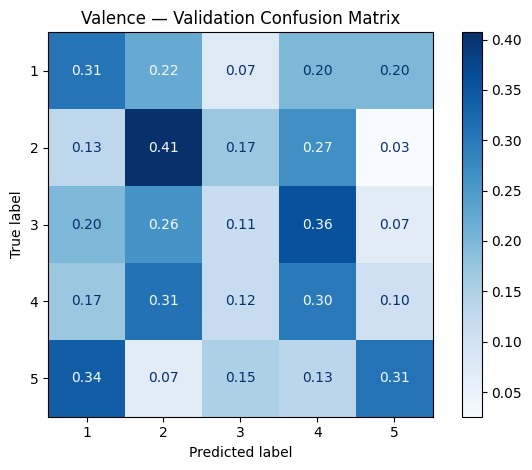

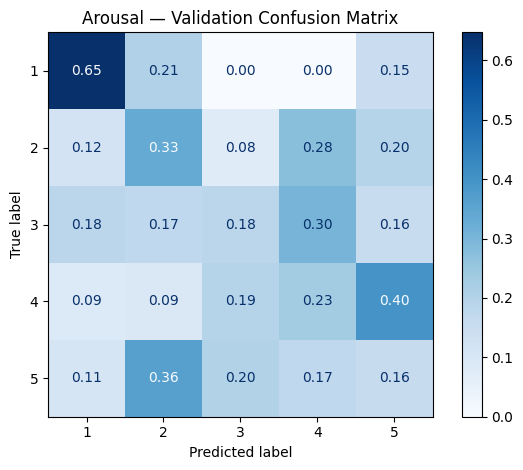

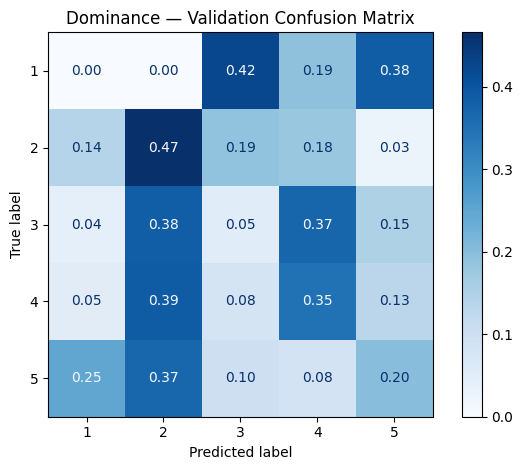

In [111]:
# Plot confusion matrices
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for target_name, (_, y_val, _) in targets.items():

    row = results_df[
        results_df["Target"] == target_name
    ].iloc[0]

    model_name = row["Model"]
    model = trained_models[(target_name, model_name)]

    predictions = model.predict(X_val_scaled)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        labels=[0, 1, 2, 3, 4],
        display_labels=[1, 2, 3, 4, 5],
        normalize="true",
        values_format=".2f",
        cmap="Blues"
    )

    plt.title(f"{target_name} — Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()

### Try binary emotion classification

In [112]:
# Prepare binary Valence labels correctly

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
from sklearn.linear_model import LogisticRegression

# Original 1–5 scores, separated using the existing subject split
y_valence_original_train = all_segment_labels[train_mask, 3]
y_valence_original_val = all_segment_labels[val_mask, 3]
y_valence_original_test = all_segment_labels[test_mask, 3]


def binary_subset(X, original_scores):
    # 1–2 = Low (0), 3 = excluded, 4–5 = High (1)
    binary_labels = np.full(
        len(original_scores), -1, dtype=np.int64
    )

    binary_labels[original_scores <= 2] = 0
    binary_labels[original_scores >= 4] = 1

    keep = binary_labels != -1

    return X[keep], binary_labels[keep]


# Each X array now uses labels from its own split
X_train_vb, y_train_vb = binary_subset(
    X_train_scaled, y_valence_original_train
)

X_val_vb, y_val_vb = binary_subset(
    X_val_scaled, y_valence_original_val
)

X_test_vb, y_test_vb = binary_subset(
    X_test_scaled, y_valence_original_test
)

print("Training shape:", X_train_vb.shape)
print("Validation shape:", X_val_vb.shape)
print("Test shape:", X_test_vb.shape)

print("\nTraining class counts:", np.bincount(y_train_vb))
print("Validation class counts:", np.bincount(y_val_vb))
print("Test class counts:", np.bincount(y_test_vb))

Training shape: (8679, 196)
Validation shape: (2434, 196)
Test shape: (2539, 196)

Training class counts: [4352 4327]
Validation class counts: [1251 1183]
Test class counts: [1058 1481]


In [113]:
# Train the model
binary_model = LogisticRegression(
    max_iter=1500,
    class_weight="balanced",
    random_state=42
)

binary_model.fit(X_train_vb, y_train_vb)

val_pred_vb = binary_model.predict(X_val_vb)

print("Validation accuracy:",
      accuracy_score(y_val_vb, val_pred_vb))

print("Validation macro-F1:",
      f1_score(
          y_val_vb,
          val_pred_vb,
          average="macro",
          zero_division=0
      ))

print("\nValidation classification report:")

print(classification_report(
    y_val_vb,
    val_pred_vb,
    labels=[0, 1],
    target_names=["Low", "High"],
    zero_division=0
))

Validation accuracy: 0.5546425636811833
Validation macro-F1: 0.5472025799843899

Validation classification report:
              precision    recall  f1-score   support

         Low       0.56      0.66      0.61      1251
        High       0.55      0.44      0.49      1183

    accuracy                           0.55      2434
   macro avg       0.55      0.55      0.55      2434
weighted avg       0.55      0.55      0.55      2434



In [114]:
# Evaluate on the test set
test_pred_vb = binary_model.predict(X_test_vb)

print("Test accuracy:",
      accuracy_score(y_test_vb, test_pred_vb))

print("Test macro-F1:",
      f1_score(
          y_test_vb,
          test_pred_vb,
          average="macro",
          zero_division=0
      ))

print("\nTest classification report:")

print(classification_report(
    y_test_vb,
    test_pred_vb,
    labels=[0, 1],
    target_names=["Low", "High"],
    zero_division=0
))

Test accuracy: 0.5124064592359197
Test macro-F1: 0.5118066039201069

Test classification report:
              precision    recall  f1-score   support

         Low       0.44      0.57      0.49      1058
        High       0.61      0.47      0.53      1481

    accuracy                           0.51      2539
   macro avg       0.52      0.52      0.51      2539
weighted avg       0.53      0.51      0.51      2539



### Extend binary classification to Arousal and Dominance

In [115]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)
import numpy as np
import pandas as pd

def prepare_binary_split(X, original_scores):
    labels = np.full(len(original_scores), -1, dtype=np.int64)
    labels[original_scores <= 2] = 0  # Low
    labels[original_scores >= 4] = 1  # High

    keep = labels != -1
    return X[keep], labels[keep]


binary_targets = {
    "Valence": (
        all_segment_labels[train_mask, 3],
        all_segment_labels[val_mask, 3],
        all_segment_labels[test_mask, 3]
    ),
    "Arousal": (
        all_segment_labels[train_mask, 4],
        all_segment_labels[val_mask, 4],
        all_segment_labels[test_mask, 4]
    ),
    "Dominance": (
        all_segment_labels[train_mask, 5],
        all_segment_labels[val_mask, 5],
        all_segment_labels[test_mask, 5]
    )
}

binary_results = []
binary_models = {}

for target_name, (scores_train, scores_val, scores_test) in binary_targets.items():

    Xtr, ytr = prepare_binary_split(X_train_scaled, scores_train)
    Xv, yv = prepare_binary_split(X_val_scaled, scores_val)
    Xte, yte = prepare_binary_split(X_test_scaled, scores_test)

    model = LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    )

    model.fit(Xtr, ytr)

    val_pred = model.predict(Xv)
    test_pred = model.predict(Xte)

    binary_models[target_name] = model

    binary_results.append({
        "Target": target_name,
        "Train samples": len(ytr),
        "Validation samples": len(yv),
        "Test samples": len(yte),
        "Validation accuracy": accuracy_score(yv, val_pred),
        "Validation macro-F1": f1_score(
            yv, val_pred, average="macro", zero_division=0
        ),
        "Test accuracy": accuracy_score(yte, test_pred),
        "Test macro-F1": f1_score(
            yte, test_pred, average="macro", zero_division=0
        ),
        "Test balanced accuracy": balanced_accuracy_score(yte, test_pred)
    })

    print(f"\n{'=' * 45}")
    print(f"{target_name} — Test classification report")
    print('=' * 45)

    print(classification_report(
        yte,
        test_pred,
        labels=[0, 1],
        target_names=["Low", "High"],
        zero_division=0
    ))

binary_results_df = pd.DataFrame(binary_results)
display(binary_results_df.round(4))


Valence — Test classification report
              precision    recall  f1-score   support

         Low       0.44      0.57      0.49      1058
        High       0.61      0.47      0.53      1481

    accuracy                           0.51      2539
   macro avg       0.52      0.52      0.51      2539
weighted avg       0.53      0.51      0.51      2539


Arousal — Test classification report
              precision    recall  f1-score   support

         Low       0.38      0.29      0.33       904
        High       0.59      0.67      0.63      1345

    accuracy                           0.52      2249
   macro avg       0.48      0.48      0.48      2249
weighted avg       0.50      0.52      0.51      2249


Dominance — Test classification report
              precision    recall  f1-score   support

         Low       0.32      0.40      0.36       778
        High       0.66      0.57      0.61      1562

    accuracy                           0.52      2340
   macro avg

,Target,Train samples,Validation samples,Test samples,Validation accuracy,Validation macro-F1,Test accuracy,Test macro-F1,Test balanced accuracy
0,Valence,8679,2434,2539,0.5546,0.5472,0.5124,0.5118,0.5210
1,Arousal,7728,2136,2249,0.5721,0.5442,0.5193,0.4776,0.4824
2,Dominance,7855,2364,2340,0.5034,0.4791,0.5184,0.4865,0.4899
